# Лабораторная работа 2. Рекомендательные системы

**Задача:** построить и сравнить несколько алгоритмов рекомендаций новостных статей на реальных логах новостного портала.

**Датасет:** EB-NeRD (*Ekstra Bladet News Recommendation Dataset*) - официальный датасет **RecSys Challenge 2024** ([recsyschallenge.com/2024](https://www.recsyschallenge.com/2024/), [recsys.eb.dk](https://recsys.eb.dk/)).

**Содержание**
1. Описание датасета
2. Разведочный анализ данных (EDA) и отчёт о качестве данных
3. Разделение на обучающую / валидационную / тестовую выборки
4. Метрики качества
5. Методы формирования рекомендаций
6. Подбор гиперпараметров на валидации
7. Оценка на тесте и сравнение методов
8. Улучшение качества рекомендаций
9. Выводы

## 1. Описание датасета

**Источник.** Ekstra Bladet - одно из крупнейших датских новостных изданий. Для RecSys Challenge 2024 компания опубликовала логи пользователей за 6 недель (27.04.2023 - 01.06.2023) и полный каталог статей. Датасет распространяется для некоммерческого исследовательского использования; он не размещён на Kaggle и не является MovieLens, т.е. удовлетворяет условию задания.

**Почему подходит:** есть явный объект рекомендации (статья), неявный отклик пользователя (клик, время чтения, глубина прокрутки) с точными временными метками, а также богатые метаданные объектов (категория, тема, тексты).

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import time
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
from implicit.als import AlternatingLeastSquares
from threadpoolctl import threadpool_limits

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (11, 4), 'figure.dpi': 110, 'axes.titleweight': 'bold'})
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:.4f}'.format)

DATA = Path('data')
SEED = 42
K = 10                      
np.random.seed(SEED)

In [2]:
articles = pd.read_parquet(DATA / 'articles.parquet')
beh_train = pd.read_parquet(DATA / 'train' / 'behaviors.parquet')
beh_val = pd.read_parquet(DATA / 'validation' / 'behaviors.parquet')
hist_train = pd.read_parquet(DATA / 'train' / 'history.parquet')
hist_val = pd.read_parquet(DATA / 'validation' / 'history.parquet')

tables = {'articles': articles, 'behaviors/train': beh_train, 'behaviors/validation': beh_val,
          'history/train': hist_train, 'history/validation': hist_val}
pd.DataFrame({name: {'строк': len(df), 'столбцов': df.shape[1],
                     'память, МБ': round(df.memory_usage(deep=True).sum() / 2**20, 1)}
              for name, df in tables.items()}).T.astype({'строк': int, 'столбцов': int})

,строк,столбцов,"память, МБ"
articles,20738,21,66.6000
behaviors/train,232887,17,69.1000
behaviors/validation,244647,17,72.6000
history/train,15143,5,7.0000
history/validation,15342,5,7.1000


In [3]:
articles.head(3).T

,0,1,2
article_id,3001353,3003065,3012771
title,Natascha var ikke den første,Kun Star Wars tjente mere,Morten Bruun fyret i SønderjyskE
subtitle,"Politiet frygter nu, at Nataschas bortfører ha...",Biografgængerne strømmer ind for at se 'Da Vin...,FODBOLD: Morten Bruun fyret med øjeblikkelig v...
last_modified_time,2023-06-29 06:20:33,2023-06-29 06:20:35,2023-06-29 06:20:39
premium,False,False,False
body,Sagen om den østriske Natascha og hendes bortf...,Vatikanet har opfordret til at boykotte filmen...,Kemien mellem spillerne i Superligaklubben Søn...
published_time,2006-08-31 08:06:45,2006-05-21 16:57:00,2006-05-01 14:28:40
image_ids,[3150850],[3006712],[3177953]
article_type,article_default,article_default,article_default
url,https://ekstrabladet.dk/krimi/article3001353.ece,https://ekstrabladet.dk/underholdning/filmogtv...,https://ekstrabladet.dk/sport/fodbold/dansk_fo...


In [4]:
display(beh_train.head(3).T)
display(hist_train.head(2).T)

,0,1,2
impression_id,149474,150528,153068
article_id,NaN,NaN,9778682.0000
impression_time,2023-05-24 07:47:53,2023-05-24 07:33:25,2023-05-24 07:09:04
read_time,13.0000,25.0000,78.0000
scroll_percentage,NaN,NaN,100.0000
device_type,2,2,1
article_ids_inview,"[9778623, 9778682, 9778669, 9778657, 9778736, ...","[9778718, 9778728, 9778745, 9778669, 9778657, ...","[9778657, 9778669, 9772866, 9776259, 9756397, ..."
article_ids_clicked,[9778657],[9778623],[9778669]
user_id,139836,143471,151570
is_sso_user,False,False,False


,0,1
user_id,13538,14241
impression_time_fixed,"[2023-04-27T10:17:43.000000, 2023-04-27T10:18:...","[2023-04-27T09:40:18.000000, 2023-04-27T09:40:..."
scroll_percentage_fixed,"[100.0, 35.0, 100.0, 24.0, 100.0, 23.0, 100.0,...","[100.0, 46.0, 100.0, 70.0, 100.0, 100.0, 100.0..."
article_id_fixed,"[9738663, 9738569, 9738663, 9738490, 9738663, ...","[9738557, 9738528, 9738533, 9738684, 9739035, ..."
read_time_fixed,"[17.0, 12.0, 4.0, 5.0, 4.0, 9.0, 5.0, 46.0, 11...","[8.0, 9.0, 28.0, 17.0, 91.0, 21.0, 14.0, 27.0,..."


## 2. Разведочный анализ данных

### 2.1 Каталог статей

Статей в каталоге: 20,738; уникальных article_id: 20,738
Диапазон дат публикации: 1998-12-27 12:05:00 — 2023-07-11 05:05:36
Доля premium-статей: 23.6%


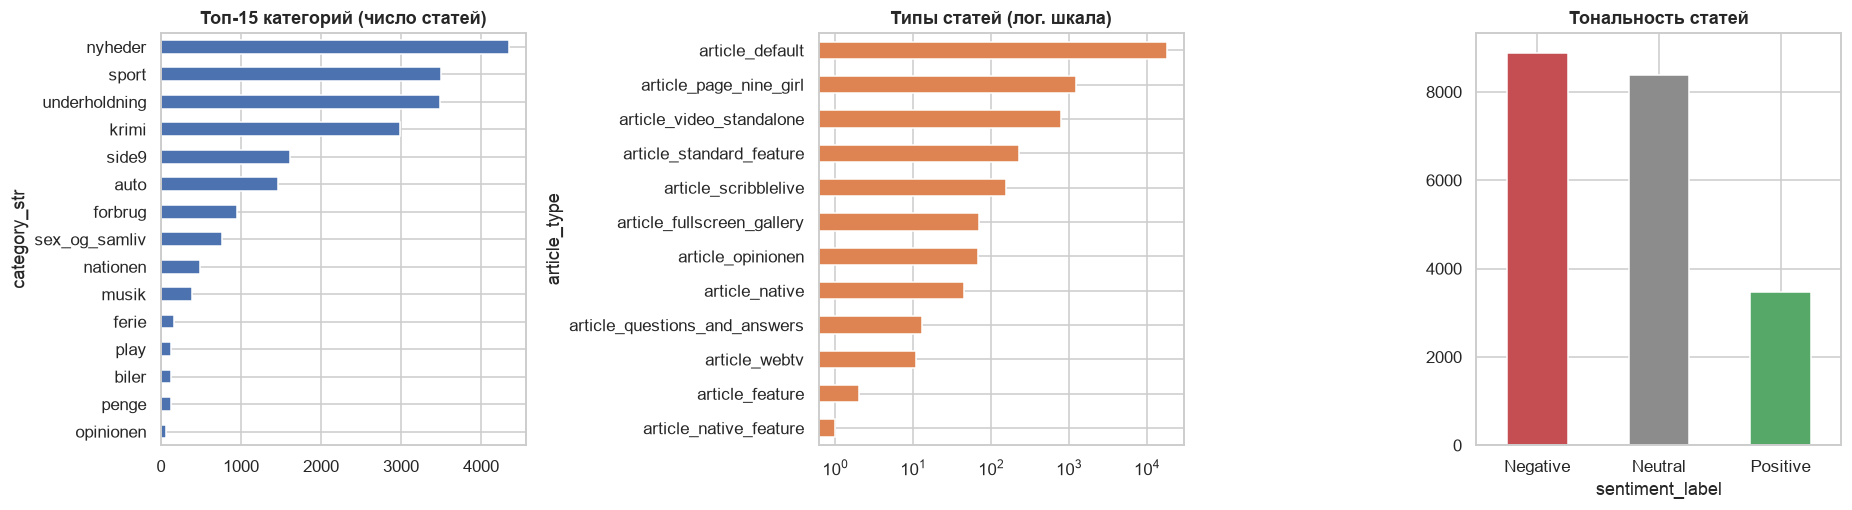

In [5]:
print(f'Статей в каталоге: {len(articles):,}; уникальных article_id: {articles.article_id.nunique():,}')
print(f'Диапазон дат публикации: {articles.published_time.min()} — {articles.published_time.max()}')
print(f'Доля premium-статей: {articles.premium.mean():.1%}')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
articles.category_str.value_counts().head(15).sort_values().plot.barh(ax=axes[0], color='C0')
axes[0].set_title('Топ-15 категорий (число статей)')
articles.article_type.value_counts().sort_values().plot.barh(ax=axes[1], color='C1', logx=True)
axes[1].set_title('Типы статей (лог. шкала)')
articles.sentiment_label.value_counts().plot.bar(ax=axes[2], color=['C3', 'C7', 'C2'], rot=0)
axes[2].set_title('Тональность статей')
plt.tight_layout(); plt.show()

Статей, опубликованных в период логов (с 2023-04-27): 6,093 (29.4%)


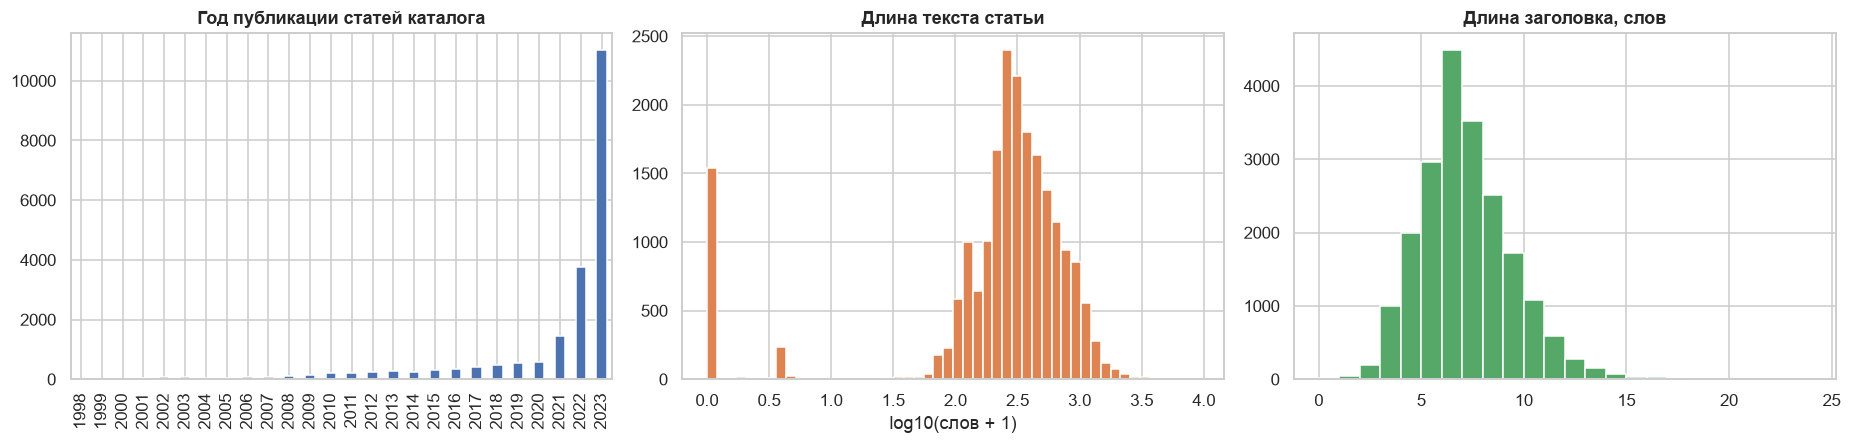

,count,mean,std,min,25%,50%,75%,max
слов в тексте,20738.0000,394.9300,355.9141,0.0000,185.2500,301.0000,510.0000,9178.0000
слов в заголовке,20738.0000,6.6856,2.2869,0.0000,5.0000,6.0000,8.0000,20.0000


In [6]:
LOG_START = pd.Timestamp('2023-04-27 07:00')
fresh = articles.published_time >= LOG_START
print(f'Статей, опубликованных в период логов (с {LOG_START.date()}): {fresh.sum():,} ({fresh.mean():.1%})')

body_words = articles.body.fillna('').str.split().str.len()
title_words = articles.title.fillna('').str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
articles.published_time.dt.year.value_counts().sort_index().plot.bar(ax=axes[0], color='C0')
axes[0].set_title('Год публикации статей каталога'); axes[0].set_xlabel('')
axes[1].hist(np.log10(body_words + 1), bins=50, color='C1')
axes[1].set_title('Длина текста статьи'); axes[1].set_xlabel('log10(слов + 1)')
axes[2].hist(title_words, bins=range(0, 25), color='C2')
axes[2].set_title('Длина заголовка, слов')
plt.tight_layout(); plt.show()
pd.DataFrame({'слов в тексте': body_words.describe(), 'слов в заголовке': title_words.describe()}).T

**Интерпретация.** - Каталог - 20 738 статей с 1998 по 2023 год, но лишь **29%** из них опубликованы в период логов: остальное архив, который почти не читают (см. ниже), т.е. «рабочий» каталог для рекомендаций гораздо меньше формального.
- Категории сильно несбалансированы: доминируют `nyheder` (новости), `sport`, `underholdning` (развлечения) и `krimi`;
- Почти все статьи обычного типа `article_default`; специальные форматы (видео, live-блоги, галереи) единичны.
- Около 24% статей premium (платные), тональность преимущественно негативная - типично для таблоида.
- Обычная статья - ~300 слов, заголовок - 6 слов; у 7% статей текст пустой (видео/галереи) - для текстовых моделей их пришлось бы описывать заголовком.

### 2.2 Лог взаимодействий (history)

Файлы `history` хранят по одной строке на пользователя со списками кликов. Разворачиваем их в «длинную» таблицу *пользователь - статья - время*. Окна `train/history` (27.04–18.05) и `validation/history` (04.05–25.05) пересекаются, поэтому сразу проверяем дубликаты.

In [7]:
HIST_COLS = {'impression_time_fixed': 'ts', 'scroll_percentage_fixed': 'scroll',
             'article_id_fixed': 'article_id', 'read_time_fixed': 'read_time'}

def explode_history(df, part):
    e = df.explode(list(HIST_COLS)).rename(columns=HIST_COLS)
    e['ts'] = pd.to_datetime(e['ts'])
    e['article_id'] = e['article_id'].astype('int64')
    e['scroll'] = e['scroll'].astype('float32')
    e['read_time'] = e['read_time'].astype('float32')
    e['part'] = part
    return e.reset_index(drop=True)

raw_log = pd.concat([explode_history(hist_train, 'train'), explode_history(hist_val, 'validation')],
                    ignore_index=True)
for part, g in raw_log.groupby('part'):
    print(f'{part:10s}: {len(g):>9,} кликов, {g.user_id.nunique():,} пользователей, {g.ts.min()} — {g.ts.max()}')

key = ['user_id', 'ts', 'article_id']
n_dup = raw_log.duplicated(key).sum()
n_dup_full = raw_log.duplicated(key + ['read_time', 'scroll']).sum()
n_dup_inside = sum(g.duplicated(key).sum() for _, g in raw_log.groupby('part'))
print(f'\nДубликатов (user, ts, article): {n_dup:,} ({n_dup / len(raw_log):.1%}), '
      f'из них полностью совпадающих строк: {n_dup_full:,}; дубликатов внутри одного файла: {n_dup_inside:,}')

log = raw_log.drop_duplicates(key).drop(columns='part').sort_values('ts').reset_index(drop=True)
print(f'После удаления дубликатов: {len(log):,} кликов, {log.user_id.nunique():,} пользователей, '
      f'{log.article_id.nunique():,} статей, период {log.ts.min()} — {log.ts.max()}')

train     : 2,426,247 кликов, 15,143 пользователей, 2023-04-27 07:00:00 — 2023-05-18 06:59:59
validation: 2,204,173 кликов, 15,342 пользователей, 2023-05-04 07:00:00 — 2023-05-25 06:59:59



Дубликатов (user, ts, article): 1,353,360 (29.2%), из них полностью совпадающих строк: 1,352,687; дубликатов внутри одного файла: 1,091


После удаления дубликатов: 3,277,060 кликов, 18,827 пользователей, 11,163 статей, период 2023-04-27 07:00:00 — 2023-05-25 06:59:59


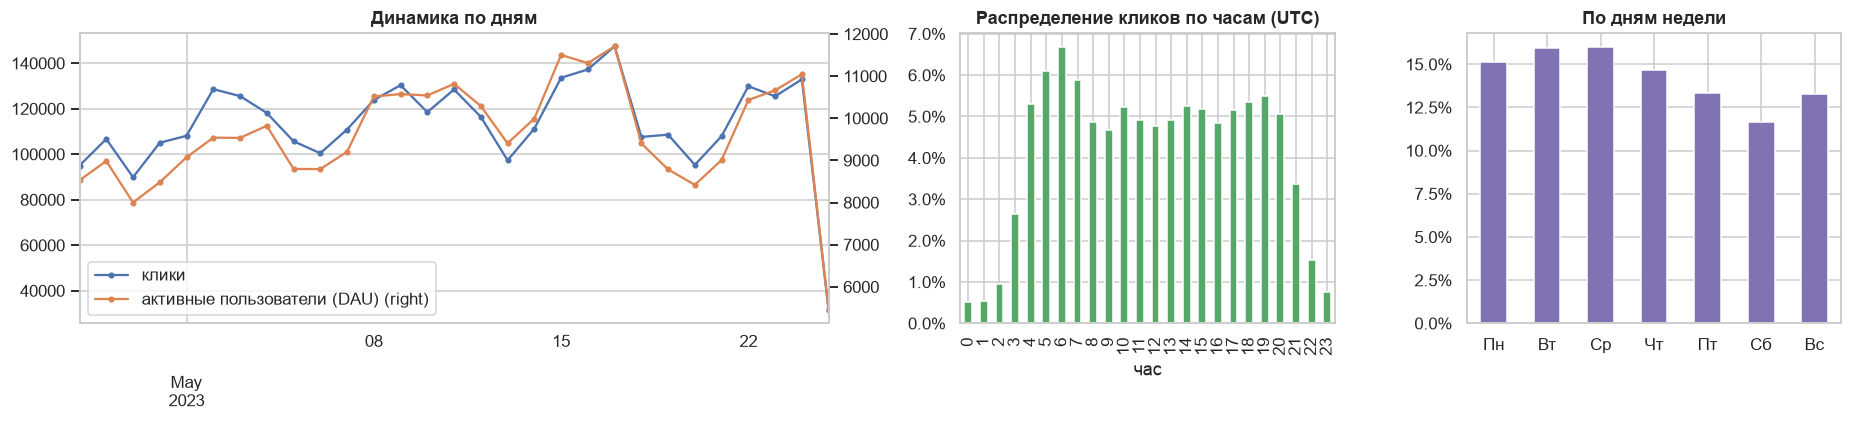

In [8]:
daily = log.set_index('ts').resample('D').agg({'user_id': ['size', 'nunique']})
daily.columns = ['клики', 'активные пользователи (DAU)']
fig, axes = plt.subplots(1, 3, figsize=(17, 4), gridspec_kw={'width_ratios': [2, 1, 1]})
daily.plot(ax=axes[0], marker='o', ms=3, secondary_y='активные пользователи (DAU)')
axes[0].set_title('Динамика по дням'); axes[0].set_xlabel('')
(log.ts.dt.hour.value_counts(normalize=True).sort_index()).plot.bar(ax=axes[1], color='C2')
axes[1].set_title('Распределение кликов по часам (UTC)'); axes[1].set_xlabel('час'); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
wd = log.ts.dt.dayofweek.value_counts(normalize=True).sort_index()
wd.index = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
wd.plot.bar(ax=axes[2], color='C4', rot=0); axes[2].set_title('По дням недели')
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.tight_layout(); plt.show()

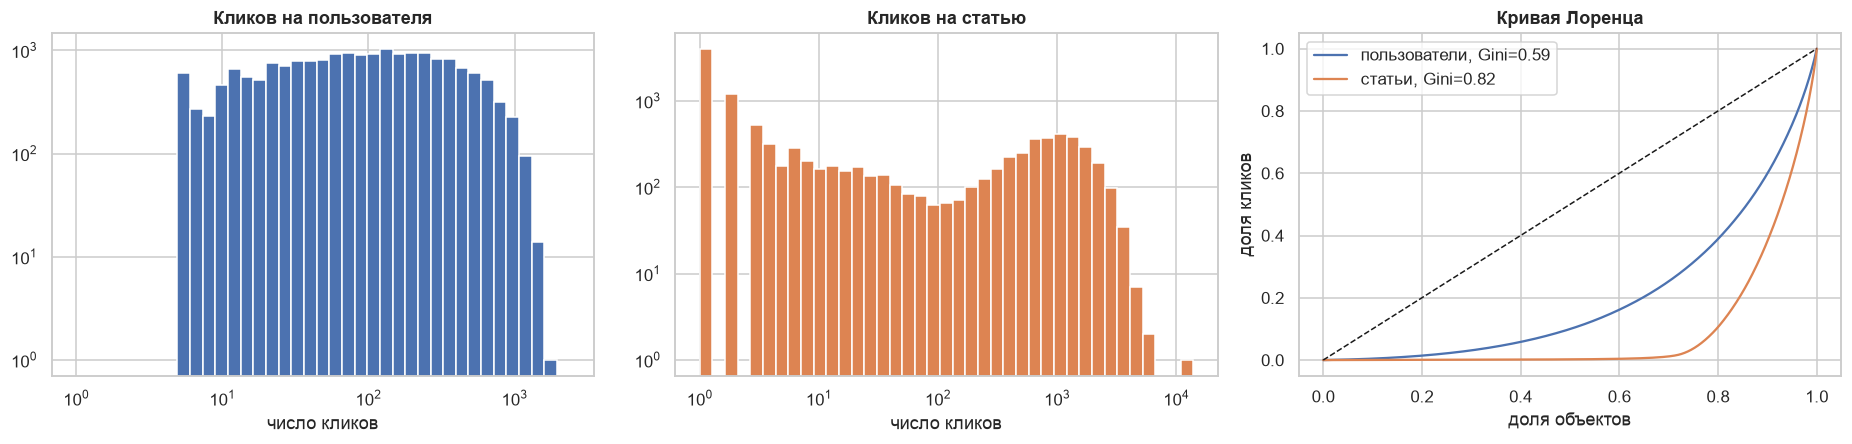

Разреженность матрицы user×item: 98.6785%
Топ-1% статей собирают 11.2% кликов, топ-10% — 61.8%
Статей с одним кликом: 36.0%


,count,mean,std,min,25%,50%,75%,95%,99%,max
кликов на пользователя,18827.0000,174.0617,215.1353,5.0000,29.0000,88.0000,235.0000,638.7000,988.4800,1896.0000
кликов на статью,11163.0000,293.5645,607.7213,1.0000,1.0000,3.0000,275.0000,1627.9000,2663.6600,11036.0000


In [9]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())

u_act = log.groupby('user_id').size()
i_pop = log.groupby('article_id').size()
n_pairs = log[['user_id', 'article_id']].drop_duplicates().shape[0]
sparsity = 1 - n_pairs / (log.user_id.nunique() * log.article_id.nunique())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
bins = np.logspace(0, np.log10(u_act.max()) + 0.1, 40)
axes[0].hist(u_act, bins=bins, color='C0'); axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_title('Кликов на пользователя'); axes[0].set_xlabel('число кликов')
bins = np.logspace(0, np.log10(i_pop.max()) + 0.1, 40)
axes[1].hist(i_pop, bins=bins, color='C1'); axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_title('Кликов на статью'); axes[1].set_xlabel('число кликов')
for s, name, c in [(u_act, 'пользователи', 'C0'), (i_pop, 'статьи', 'C1')]:
    v = np.sort(s.values)
    axes[2].plot(np.linspace(0, 1, len(v)), np.cumsum(v) / v.sum(), label=f'{name}, Gini={gini(v):.2f}', color=c)
axes[2].plot([0, 1], [0, 1], 'k--', lw=1)
axes[2].set_title('Кривая Лоренца'); axes[2].set_xlabel('доля объектов'); axes[2].set_ylabel('доля кликов'); axes[2].legend()
plt.tight_layout(); plt.show()

top1 = i_pop.sort_values(ascending=False)
print(f'Разреженность матрицы user×item: {sparsity:.4%}')
print(f'Топ-1% статей собирают {top1.head(int(len(top1) * 0.01)).sum() / top1.sum():.1%} кликов, '
      f'топ-10% — {top1.head(int(len(top1) * 0.1)).sum() / top1.sum():.1%}')
print(f'Статей с одним кликом: {(i_pop == 1).mean():.1%}')
pd.DataFrame({'кликов на пользователя': u_act.describe(percentiles=[.25, .5, .75, .95, .99]),
              'кликов на статью': i_pop.describe(percentiles=[.25, .5, .75, .95, .99])}).T

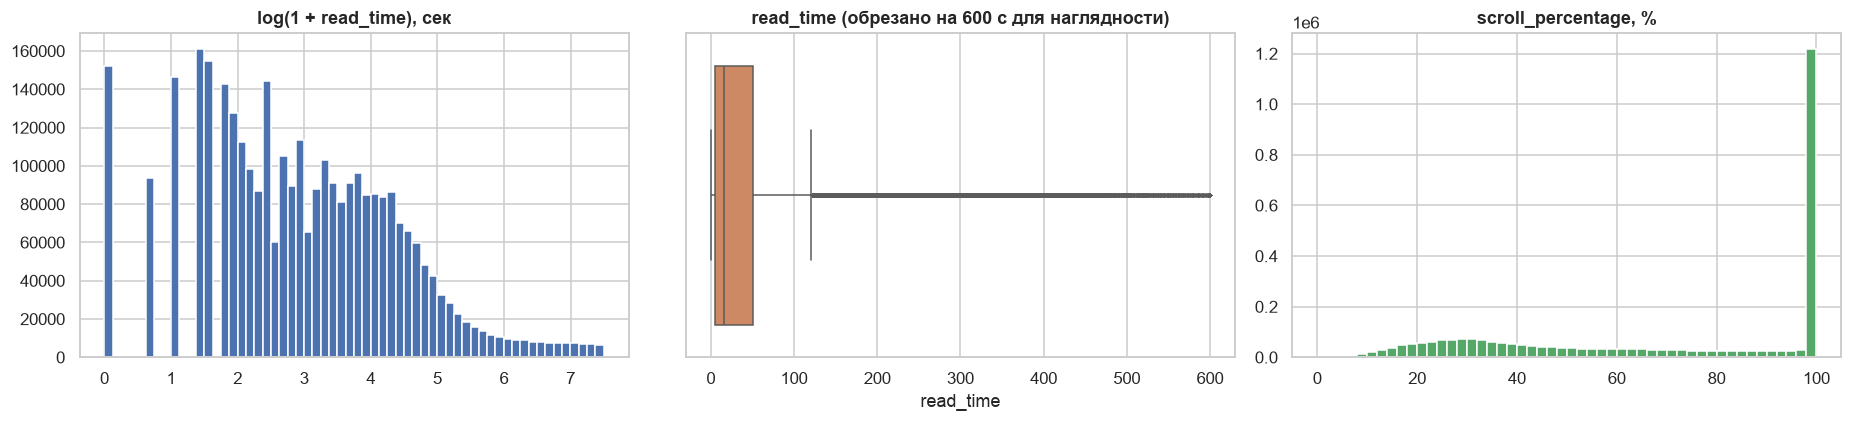

read_time: медиана 16 с, Q3+1.5·IQR = 120 с → выбросов по IQR: 9.7%
read_time = 0: 4.6%; read_time ≥ 1800 (обрезка): 0.00%; read_time < 3 с: 12.0%
scroll пропущен: 10.1%; scroll = 100%: 36.4%


Корреляция Спирмена read_time ~ scroll: 0.52


In [10]:
rt, sc = log.read_time, log.scroll
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].hist(np.log1p(rt), bins=60, color='C0'); axes[0].set_title('log(1 + read_time), сек')
sns.boxplot(x=rt.clip(upper=600), ax=axes[1], color='C1', fliersize=1)
axes[1].set_title('read_time (обрезано на 600 с для наглядности)')
axes[2].hist(sc.dropna(), bins=50, color='C2'); axes[2].set_title('scroll_percentage, %')
plt.tight_layout(); plt.show()

q1, q3 = rt.quantile([.25, .75])
iqr_hi = q3 + 1.5 * (q3 - q1)
print(f'read_time: медиана {rt.median():.0f} с, Q3+1.5·IQR = {iqr_hi:.0f} с → выбросов по IQR: {(rt > iqr_hi).mean():.1%}')
print(f'read_time = 0: {(rt == 0).mean():.1%}; read_time ≥ 1800 (обрезка): {(rt >= 1800).mean():.2%}; read_time < 3 с: {(rt < 3).mean():.1%}')
print(f'scroll пропущен: {sc.isna().mean():.1%}; scroll = 100%: {(sc == 100).mean():.1%}')
print(f'Корреляция Спирмена read_time ~ scroll: {log[["read_time", "scroll"]].corr("spearman").iloc[0, 1]:.2f}')

**Свежесть контента.** Для новостей обычно - короткий «срок жизни» статьи. Посчитаем возраст статьи в момент клика (время клика - время публикации) и время, за которое статья набирает 90% своих кликов.

Квантили возраста статьи в момент клика, часов: {0.25: 0.6, 0.5: 1.4, 0.75: 3.7, 0.9: 9.8, 0.99: 3621.9}
Кликов по статьям старше 7 дней: 2.5%


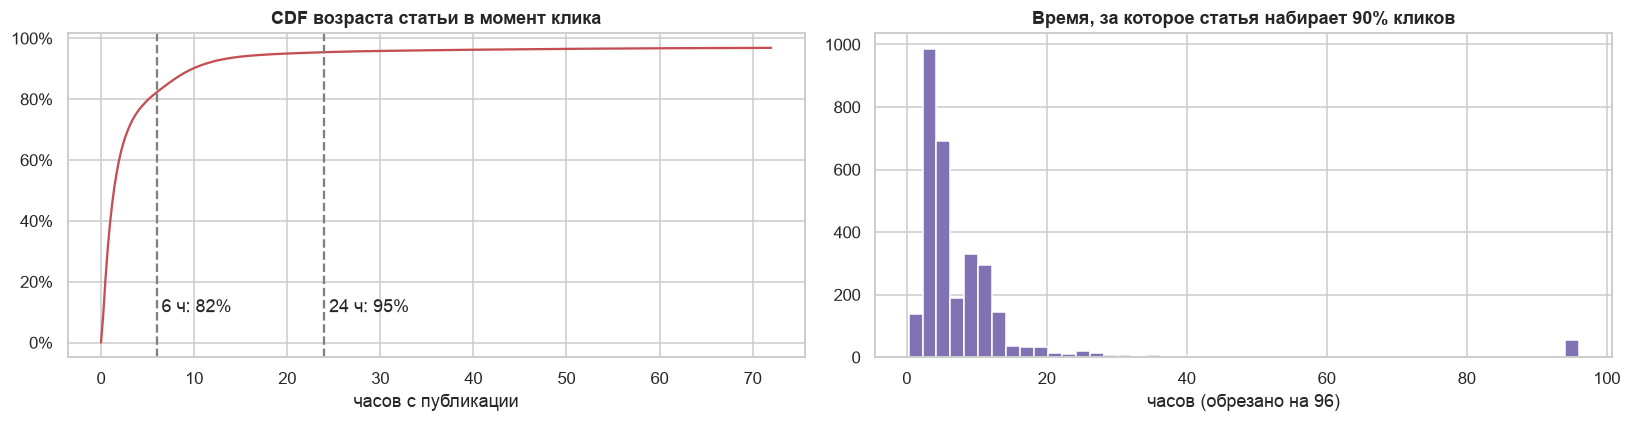

Медианный «срок жизни» статьи (90% кликов): 5.1 ч, статей в выборке: 3,069


In [11]:
pub = articles.set_index('article_id').published_time
cat_of = articles.set_index('article_id').category_str
log['age_h'] = (log.ts - log.article_id.map(pub)).dt.total_seconds() / 3600

age = log.age_h.dropna()
q = age.quantile([.25, .5, .75, .9, .99])
print('Квантили возраста статьи в момент клика, часов:', {k: round(v, 1) for k, v in q.items()})
print(f'Кликов по статьям старше 7 дней: {(age > 24 * 7).mean():.1%}')

art_life = (log[log.article_id.map(pub) >= LOG_START].groupby('article_id')
            .filter(lambda g: len(g) >= 20).groupby('article_id').age_h.quantile(0.9))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
xs = np.linspace(0, 72, 300)
axes[0].plot(xs, [(age.clip(lower=0) <= x).mean() for x in xs], color='C3')
axes[0].set_title('CDF возраста статьи в момент клика'); axes[0].set_xlabel('часов с публикации')
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
for v in [6, 24]:
    axes[0].axvline(v, ls='--', c='gray'); axes[0].text(v + 0.5, 0.1, f'{v} ч: {(age <= v).mean():.0%}')
axes[1].hist(art_life.clip(upper=96), bins=48, color='C4')
axes[1].set_title('Время, за которое статья набирает 90% кликов'); axes[1].set_xlabel('часов (обрезано на 96)')
plt.tight_layout(); plt.show()
print(f'Медианный «срок жизни» статьи (90% кликов): {art_life.median():.1f} ч, статей в выборке: {len(art_life):,}')

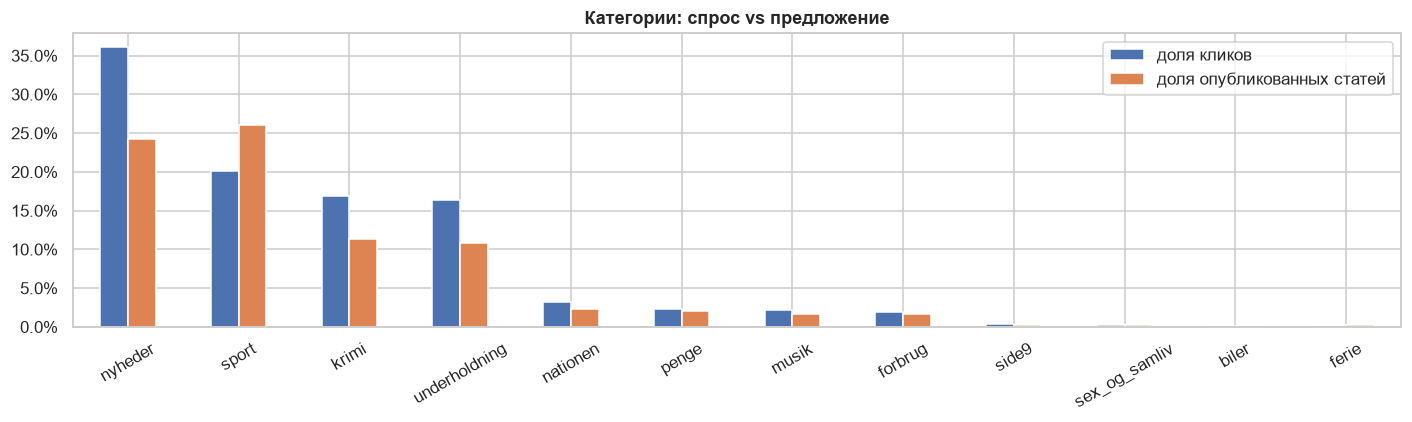

Пар (пользователь, статья) с повторным чтением: 10.9%; доля кликов-повторов: 15.2%


In [12]:
clicks_cat = log.article_id.map(cat_of).value_counts(normalize=True)
catalog_cat = articles.loc[fresh, 'category_str'].value_counts(normalize=True)
cmp = pd.DataFrame({'доля кликов': clicks_cat, 'доля опубликованных статей': catalog_cat}).fillna(0)
cmp = cmp.sort_values('доля кликов', ascending=False).head(12)
ax = cmp.plot.bar(figsize=(13, 4), rot=30)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_title('Категории: спрос vs предложение')
plt.tight_layout(); plt.show()

pair_cnt = log.groupby(['user_id', 'article_id']).size()
print(f'Пар (пользователь, статья) с повторным чтением: {(pair_cnt > 1).mean():.1%}; '
      f'доля кликов-повторов: {1 - len(pair_cnt) / len(log):.1%}')

**Интерпретация.** - **Объём и активность.** После удаления дубликатов - 3,28 млн кликов 18,8 тыс. пользователей по 11,2 тыс. статей. Медианный пользователь сделал 88 кликов за 4 недели, но распределение с тяжёлым хвостом (максимум ~1,9 тыс.).
- **Длинный хвост статей.** Медиана - 3 клика на статью при среднем 294; 36% статей кликнуты один раз, топ-10% статей дают 62% кликов (Gini статей существенно выше, чем у пользователей). Матрица разрежена на 98,7%. Следствие: популярность - сильный сигнал, а у большинства статей слишком мало данных для коллаборативных моделей.
- **Сезонность.** Ярко выраженный суточный цикл: пик в 4–7 UTC (утро по Копенгагену), ночью активность почти нулевая; по будням активность выше, чем в выходные. Ближе к концу периода общий трафик растёт. Падение в последний день - неполные сутки (лог заканчивается 25.05 в 07:00).
- **Время чтения и прокрутка.** Медиана чтения 16 с; 4,6% кликов с нулевым временем и 12% короче 3 с - «отскоки» (кликнул и ушёл). По правилу IQR ~10% значений - выбросы сверху, но это не ошибки, а реально долгое чтение длинных материалов, поэтому их не удаляем, а берём логарифм. Прокрутка и время чтения умеренно связаны (ρ Спирмена = 0,52).
- **Свежесть.** Медианный возраст статьи в момент клика - **1,4 часа**, 82% кликов приходится на первые 6 часов после публикации, 95% - на первые сутки; статья набирает 90% кликов в среднем за ~5 часов. Это определяет весь дизайн эксперимента: статьи «умирают» быстрее, чем длится тестовый период, а значит большая часть тестовых кликов придётся на новые (холодные) статьи.
- **Спрос vs предложение.** `nyheder` и `krimi` читают заметно чаще, чем их доля в публикациях; часть категорий (например, `sport`) публикуется больше, чем читается.
- **Повторное потребление.** 15% кликов - повторные открытия той же статьи (11% пар). В рекомендациях уже прочитанное исключаем.

### 2.3 Журнал показов (behaviors)

Показов: 477,534; пользователей: 18,827; сессий: 235,038
Статей в блоке (inview): медиана 9, среднее 11.5; кликов в показе: среднее 1.006, ровно 1 клик — 99.5%
Средний CTR блока = 1 / |inview| ≈ 0.119
Показы на главной странице (article_id = NaN): 70.3%


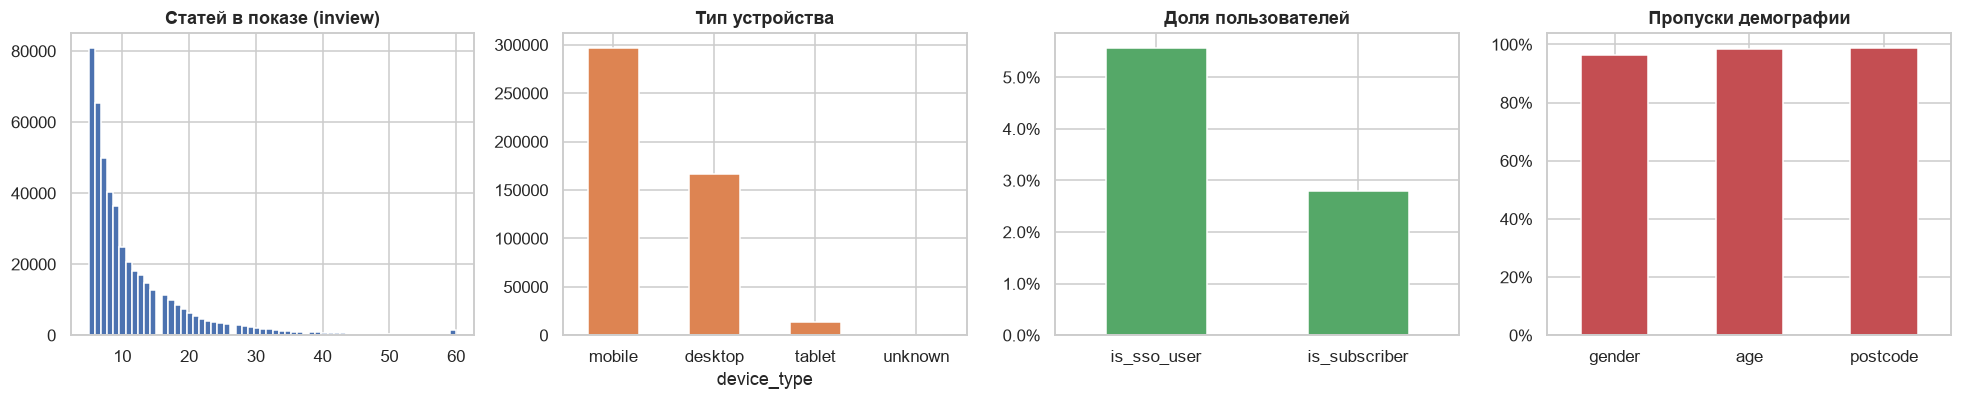

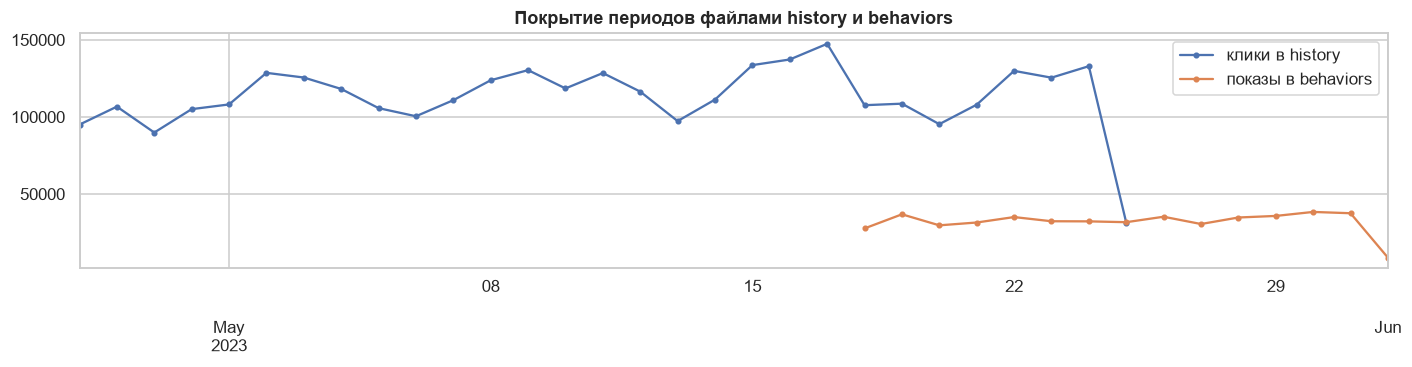

Кликов из behaviors/train, которые уже есть в объединённой history: 87.7%


In [13]:
beh = pd.concat([beh_train.assign(part='train'), beh_val.assign(part='validation')], ignore_index=True)
beh['n_inview'] = beh.article_ids_inview.str.len()
beh['n_clicked'] = beh.article_ids_clicked.str.len()

print(f'Показов: {len(beh):,}; пользователей: {beh.user_id.nunique():,}; сессий: {beh.session_id.nunique():,}')
print(f'Статей в блоке (inview): медиана {beh.n_inview.median():.0f}, среднее {beh.n_inview.mean():.1f}; '
      f'кликов в показе: среднее {beh.n_clicked.mean():.3f}, ровно 1 клик — {(beh.n_clicked == 1).mean():.1%}')
print(f'Средний CTR блока = 1 / |inview| ≈ {(beh.n_clicked / beh.n_inview).mean():.3f}')
print(f'Показы на главной странице (article_id = NaN): {beh.article_id.isna().mean():.1%}')

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
axes[0].hist(beh.n_inview.clip(upper=60), bins=60, color='C0'); axes[0].set_title('Статей в показе (inview)')
beh.device_type.map({0: 'unknown', 1: 'desktop', 2: 'mobile', 3: 'tablet'}).value_counts().plot.bar(ax=axes[1], rot=0, color='C1')
axes[1].set_title('Тип устройства')
users = beh.drop_duplicates('user_id')
users[['is_sso_user', 'is_subscriber']].mean().plot.bar(ax=axes[2], rot=0, color='C2')
axes[2].set_title('Доля пользователей'); axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1))
users[['gender', 'age', 'postcode']].isna().mean().plot.bar(ax=axes[3], rot=0, color='C3')
axes[3].set_title('Пропуски демографии'); axes[3].yaxis.set_major_formatter(mtick.PercentFormatter(1))
plt.tight_layout(); plt.show()

per_day = beh.set_index('impression_time').resample('D').size()
log_clicks = log.set_index('ts').resample('D').size()
ax = pd.DataFrame({'клики в history': log_clicks, 'показы в behaviors': per_day}).plot(figsize=(13, 3.5), marker='o', ms=3)
ax.set_title('Покрытие периодов файлами history и behaviors'); plt.tight_layout(); plt.show()

clicked = beh_train[['user_id', 'article_ids_clicked']].explode('article_ids_clicked')
clicked_pairs = pd.MultiIndex.from_arrays([clicked.user_id, clicked.article_ids_clicked.astype('int64')])
log_pairs = pd.MultiIndex.from_arrays([log.user_id, log.article_id])
print(f'Кликов из behaviors/train, которые уже есть в объединённой history: {clicked_pairs.isin(log_pairs).mean():.1%}')

**Интерпретация.** - В показе в среднем ~11 статей (медиана 9), и почти всегда (99,5%) ровно один клик, т.е. базовый CTR блока ≈ 12%. 70% показов — на главной странице.
- Подавляющая часть трафика — с мобильных устройств; лишь небольшая доля пользователей авторизована (SSO) или имеет подписку.
- Демография практически отсутствует: пол не указан у 93%, возраст у 97%, почтовый индекс у 98% пользователей — использовать её как признаки нельзя, это аргумент в пользу моделей только на взаимодействиях.
- `behaviors` покрывают лишь последние 2 недели и после 25.05 содержат на порядок меньше событий, чем полный лог `history`; 88% кликов из `behaviors/train` уже есть в `history`. Поэтому для моделирования используется `history`.

### 2.4 Отчёт о качестве данных

In [14]:
def quality_report(df, name):
    rows = {}
    for c in df.columns:
        s = df[c]
        listlike = s.dtype == object and s.dropna().map(lambda v: hasattr(v, '__len__') and not isinstance(v, str)).any()
        rows[c] = {'тип': 'list' if listlike else str(s.dtype),
                   'пропуски, %': 100 * s.isna().mean(),
                   'пустые списки, %': 100 * (s.dropna().map(len) == 0).mean() if listlike else 0.0,
                   'уникальных': s.nunique() if not listlike else np.nan}
    out = pd.DataFrame(rows).T
    out.insert(0, 'таблица', name)
    return out

qr = pd.concat([quality_report(articles, 'articles'), quality_report(beh, 'behaviors'),
                quality_report(log.drop(columns='age_h'), 'history (развёрнутая)')])
qr[(qr['пропуски, %'] > 0) | (qr['пустые списки, %'] > 0)].round(2)

,таблица,тип,"пропуски, %","пустые списки, %",уникальных
image_ids,articles,list,9.0558,0.0000,NaN
ner_clusters,articles,list,0.0000,26.2465,NaN
entity_groups,articles,list,0.0000,26.2465,NaN
topics,articles,list,0.0000,0.9065,NaN
subcategory,articles,list,0.0000,30.6828,NaN
total_inviews,articles,float64,51.9336,0.0000,9573
total_pageviews,articles,float64,52.4737,0.0000,8172
total_read_time,articles,float32,52.4737,0.0000,9610
article_id,behaviors,float64,70.3219,0.0000,2908
scroll_percentage,behaviors,float32,70.7709,0.0000,94


In [15]:
not_in_catalog = ~log.article_id.isin(articles.article_id)
neg_age = log.age_h < 0
issues = pd.Series({
    'дубликаты article_id в каталоге': articles.article_id.duplicated().sum(),
    'дубликаты impression_id в behaviors': beh.duplicated(['impression_id', 'part']).sum(),
    'дубликаты user_id внутри одного файла history': hist_train.user_id.duplicated().sum() + hist_val.user_id.duplicated().sum(),
    'дубликаты кликов (пересечение окон history)': n_dup,
    'клики по статьям вне каталога': not_in_catalog.sum(),
    'клики раньше даты публикации': neg_age.sum(),
    'клики с read_time = 0': (log.read_time == 0).sum(),
    'клики с read_time на верхней границе 1800 с': (log.read_time >= 1800).sum(),
    'статьи без текста (body пуст)': (articles.body.fillna('').str.len() == 0).sum(),
}, name='количество').to_frame()
issues['доля'] = [v / n for v, n in zip(issues['количество'],
                  [len(articles), len(beh), len(hist_train) + len(hist_val), len(raw_log), len(log), len(log),
                   len(log), len(log), len(articles)])]
display(issues.style.format({'количество': '{:,}', 'доля': '{:.2%}'}))

q1, q3 = u_act.quantile([.25, .75])
hi = q3 + 3 * (q3 - q1)
heavy = u_act[u_act > hi]
days = (log.ts.max() - log.ts.min()).days
print(f'Пользователи-выбросы по активности (> Q3 + 3·IQR = {hi:.0f} кликов): {len(heavy):,} ({len(heavy) / len(u_act):.1%}), '
      f'они дают {heavy.sum() / u_act.sum():.1%} кликов; максимум {u_act.max():,} кликов ≈ {u_act.max() / days:.0f} в день')
print(f'Возраст «отрицательных» кликов, часов: {log.loc[neg_age, "age_h"].describe()[["min", "50%", "max"]].round(2).to_dict()}')

,количество,доля
дубликаты article_id в каталоге,0,0.00%
дубликаты impression_id в behaviors,0,0.00%
дубликаты user_id внутри одного файла history,0,0.00%
дубликаты кликов (пересечение окон history),"1,353,360",29.23%
клики по статьям вне каталога,0,0.00%
клики раньше даты публикации,562,0.02%
клики с read_time = 0,"152,059",4.64%
клики с read_time на верхней границе 1800 с,32,0.00%
статьи без текста (body пуст),"1,542",7.44%


Пользователи-выбросы по активности (> Q3 + 3·IQR = 853 кликов): 387 (2.1%), они дают 12.1% кликов; максимум 1,896 кликов ≈ 70 в день
Возраст «отрицательных» кликов, часов: {'min': -0.74, '50%': -0.31, 'max': -0.0}


### 2.5 Целевая переменная и предобработка

**Что рекомендуем.** Объект рекомендации - **новостная статья** (`article_id`). Задача: для каждого пользователя сформировать top-$K$ ($K=10$) список статей, которые он ещё не читал и **кликнет (прочитает) в ближайшие 24 часа**.

**Целевая переменная** — бинарный неявный отклик $r_{ui}=1$, если пользователь $u$ кликнул статью $i$ (implicit feedback; отрицательных оценок в данных нет, некликнутые статьи — «неизвестно», а не «не нравится»). Время чтения используется как *уверенность* в положительном отклике (вес в ALS), а не как цель.

**Предобработка:**
1. Удаляем дубликаты, возникшие из-за пересечения окон `train/history` и `validation/history`.
2. Основой для обучения берём полный лог кликов `history` (27.04 – 25.05): он плотный и содержит все клики пользователей. `behaviors` используются только в EDA — их клики почти полностью содержатся в `history`, а за последнюю неделю (25.05 – 01.06) есть только разреженная выборка показов без полной истории.
3. Клики по статьям вне каталога удаляем (их нет).
4. `read_time` не обрезаем дополнительно (он уже ограничен 1800 с), пропуски заполняем 0; для весов используем $\log(1+\text{read\_time})$, что гасит выбросы.
5. Короткие клики (read_time ≈ 0) и «тяжёлых» пользователей **не удаляем**: клик — это и есть целевое событие, а аномально активные пользователи дают малую долю кликов и не похожи на ботов (активность ~ десятки статей в день).
6. Клики «до публикации» оставляем: это артефакт обновления `published_time` при правке статьи, а не ошибка взаимодействия.

In [16]:
log = log[log.article_id.isin(articles.article_id)].copy()
log['read_time'] = log.read_time.fillna(0)
log = log[['user_id', 'article_id', 'ts', 'read_time', 'scroll', 'age_h']].reset_index(drop=True)
print(f'Итоговый лог: {len(log):,} кликов, {log.user_id.nunique():,} пользователей, {log.article_id.nunique():,} статей')

Итоговый лог: 3,277,060 кликов, 18,827 пользователей, 11,163 статей


### 2.6 Выводы по EDA

1. Датасет описывает классическую задачу top-N рекомендаций по **неявному отклику**: объект — новостная статья, целевое событие — клик. Явных оценок и надёжной демографии нет.
2. Данные очень **разрежены** (98,7%) и имеют **длинный хвост**: малая доля статей собирает большую часть кликов → популярность будет сильным бейзлайном, а коллаборативным моделям не хватит данных по большинству статей.
3. **Короткий жизненный цикл контента** (медиана возраста при клике 1,4 ч, 95% кликов в первые сутки) — ключевая особенность новостей. Ожидаемо сильная проблема холодного старта объектов и важность учёта времени: модель должна понимать не только «что нравится», но и «что актуально сейчас».
4. Есть выраженная суточная и недельная сезонность → разбиение на выборки должно быть строго временным.
5. После удаления дубликатов (29% строк) качество данных достаточное; выбросы во времени чтения и активные пользователи не требуют удаления.

## 3. Разделение на обучающую и тестовую выборки

**Схема — глобальное временное разбиение (global temporal split).** Все взаимодействия до момента $T$ — обучение, следующие 24 часа — тест. В отличие от случайного разбиения, это исключает «подглядывание в будущее» (модель не знает, какие статьи станут популярными завтра) и воспроизводит реальный сценарий: модель обучается ночью и обслуживает пользователей следующие сутки.

- **Тест:** $T_{test}$ = 24.05.2023 07:00, тестовое окно $[T_{test}, T_{test}+24ч)$ — последние сутки полного лога.
- **Валидация (для подбора гиперпараметров):** то же самое со сдвигом на сутки назад, $T_{val} = T_{test} - 24ч$. Тестовая выборка при подборе не используется.
- **Окно обучения:** последние $D$ дней до $T$ (по умолчанию 14; выбор $D$ проверяется на валидации). Старые статьи практически не читаются, и длинная история лишь добавляет «мёртвые» объекты.

**Состав тестовой выборки (ground truth).** Для каждого пользователя — множество статей, кликнутых в тестовом окне, при условиях:
- пользователь есть в обучении (тёплые пользователи; холодных пользователей коллаборативные модели обслуживать не умеют — им отдаётся MostPop);
- статья есть в обучении (тёплые статьи: модели не могут рекомендовать объект, о котором ничего не знают);
- пара (пользователь, статья) не встречалась в обучении — уже прочитанное не рекомендуем.

Доля отброшенных «холодных» кликов выводится явно — это важная характеристика задачи.

In [ ]:
@dataclass
class Split:
    name: str
    T: pd.Timestamp
    train: pd.DataFrame
    users: pd.Index
    items: pd.Index
    X: sp.csr_matrix               
    W: sp.csr_matrix               
    eval_users: np.ndarray        
    gt: list                      
    stats: dict = field(default_factory=dict)

    @property
    def n_items(self):
        return len(self.items)

    def recent_counts(self, hours):
        recent = self.train[self.train.ts >= self.T - pd.Timedelta(hours=hours)]
        idx = self.items.get_indexer(recent.article_id)
        return np.bincount(idx, minlength=self.n_items).astype(np.float32)


def make_split(log, T, train_days=14, test_hours=24, name=''):
    T = pd.Timestamp(T)
    train = log[(log.ts >= T - pd.Timedelta(days=train_days)) & (log.ts < T)]
    test = log[(log.ts >= T) & (log.ts < T + pd.Timedelta(hours=test_hours))]

    ui = train.groupby(['user_id', 'article_id'], as_index=False).agg(read_time=('read_time', 'sum'))
    users, items = pd.Index(np.sort(ui.user_id.unique())), pd.Index(np.sort(ui.article_id.unique()))
    r, c = users.get_indexer(ui.user_id), items.get_indexer(ui.article_id)
    shape = (len(users), len(items))
    X = sp.csr_matrix((np.ones(len(ui), np.float32), (r, c)), shape=shape)
    W = sp.csr_matrix((1 + np.log1p(ui.read_time.values).astype(np.float32), (r, c)), shape=shape)

    t = test.drop_duplicates(['user_id', 'article_id'])
    warm_u = users.get_indexer(t.user_id) >= 0
    warm_i = items.get_indexer(t.article_id) >= 0
    t_warm = t[warm_u & warm_i].merge(ui[['user_id', 'article_id']], how='left', indicator=True)
    repeat = (t_warm._merge == 'both').sum()
    t_warm = t_warm[t_warm._merge == 'left_only']
    gt = t_warm.groupby('user_id').article_id.apply(lambda s: items.get_indexer(s))

    stats = {'train: кликов': len(train), 'train: пользователей': len(users), 'train: статей': len(items),
             'train: плотность': X.nnz / (shape[0] * shape[1]),
             'test: пар (user, item)': len(t), 'test: пользователей': t.user_id.nunique(),
             'test: доля пар с холодной статьёй': 1 - warm_i.mean(),
             'test: доля пар с холодным пользователем': 1 - warm_u.mean(),
             'test: доля повторных прочтений': repeat / len(t),
             'eval: пар': len(t_warm), 'eval: пользователей': len(gt),
             'eval: релевантных на пользователя': len(t_warm) / max(len(gt), 1)}
    return Split(name, T, train, users, items, X, W,
                 users.get_indexer(gt.index), list(gt.values), stats)


def split_stats(*splits):
    fmt = lambda v: f'{v:.2%}' if v < 1 else f'{v:,.0f}' if float(v).is_integer() else f'{v:,.1f}'
    return pd.DataFrame({s.name: s.stats for s in splits}).map(fmt)


T_TEST = pd.Timestamp('2023-05-24 07:00')
T_VAL = T_TEST - pd.Timedelta(hours=24)
val = make_split(log, T_VAL, name='validation')
test = make_split(log, T_TEST, name='test')
split_stats(val, test)

,validation,test
train: кликов,"1,666,269","1,664,712"
train: пользователей,"17,987","18,265"
train: статей,"7,079","7,176"
train: плотность,1.11%,1.08%
"test: пар (user, item)","110,008","117,224"
test: пользователей,"10,730","11,104"
test: доля пар с холодной статьёй,89.37%,87.89%
test: доля пар с холодным пользователем,2.87%,3.09%
test: доля повторных прочтений,1.13%,1.08%
eval: пар,"10,287","12,672"


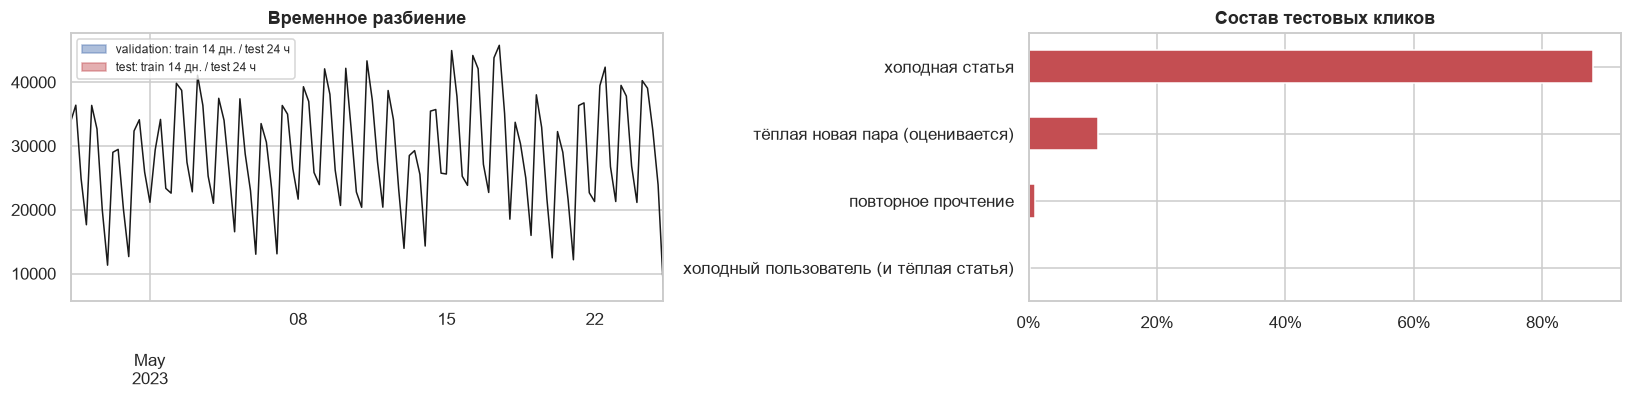

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
for s, c in [(val, 'C0'), (test, 'C3')]:
    axes[0].axvspan(s.T - pd.Timedelta(days=14), s.T, alpha=0.15, color=c)
    axes[0].axvspan(s.T, s.T + pd.Timedelta(hours=24), alpha=0.45, color=c, label=f'{s.name}: train 14 дн. / test 24 ч')
log.set_index('ts').resample('6h').size().plot(ax=axes[0], color='k', lw=1)
axes[0].set_title('Временное разбиение'); axes[0].legend(loc='upper left', fontsize=8); axes[0].set_xlabel('')

st = test.stats
parts = pd.Series({'холодная статья': st['test: доля пар с холодной статьёй'],
                   'повторное прочтение': st['test: доля повторных прочтений'],
                   'тёплая новая пара (оценивается)': st['eval: пар'] / st['test: пар (user, item)']})
parts['холодный пользователь (и тёплая статья)'] = 1 - parts.sum()
parts.sort_values().plot.barh(ax=axes[1], color='C3')
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].set_title('Состав тестовых кликов')
plt.tight_layout(); plt.show()

**Итог разбиения.** В обучении (14 дней) — 1,66 млн кликов, 18,3 тыс. пользователей и 7,2 тыс. статей (плотность ~1%). В тестовых сутках — 117 тыс. пар (пользователь, статья), из них **88% приходится на статьи, которых не было в обучении** (опубликованы уже после $T$), 3% — на холодных пользователей и ~1% — на повторные прочтения. Для оценки остаётся 12,7 тыс. пар у 4,7 тыс. пользователей (в среднем 2,7 релевантных статьи на человека). Это подтверждает вывод EDA: в новостях основная часть спроса — холодный старт, и коллаборативные модели в принципе могут отвечать лишь за ~12% кликов следующего дня. Валидационное разбиение имеет практически такую же структуру, что делает подбор параметров на нём репрезентативным.

## 4. Метрики качества

Обозначения: $U$ — пользователи тестовой выборки, $R_u$ — список из $K$ рекомендаций, $G_u$ — множество релевантных (кликнутых в тесте) статей, $rel_u(k)=1$, если $k$-я рекомендация релевантна. Все метрики усредняются по пользователям, $K=10$.

**Метрики точности (accuracy):**

| Метрика | Формула | Смысл |
|---|---|---|
| Precision@K | $\frac{\lvert R_u \cap G_u\rvert}{K}$ | доля «попаданий» в выдаче |
| Recall@K | $\frac{\lvert R_u \cap G_u\rvert}{\lvert G_u\rvert}$ | доля релевантного, которую нашла модель |
| HitRate@K | $\mathbb{1}[\lvert R_u \cap G_u\rvert>0]$ | доля пользователей, получивших хотя бы одну полезную рекомендацию |

**Метрики ранжирования** (учитывают позицию):

| Метрика | Формула |
|---|---|
| nDCG@K | $\frac{DCG}{IDCG},\; DCG=\sum_{k=1}^{K}\frac{rel_u(k)}{\log_2(k+1)}$, IDCG — DCG идеального списка |
| MAP@K | $\frac{1}{\min(\lvert G_u\rvert,K)}\sum_{k=1}^{K} P@k\cdot rel_u(k)$ |
| MRR@K | $\frac{1}{\text{rank первого попадания}}$ (0, если попаданий нет) |

**Метрики, специфичные для рекомендательных систем (beyond-accuracy):**

| Метрика | Формула | Смысл |
|---|---|---|
| Coverage@K | $\frac{\lvert\bigcup_u R_u\rvert}{\lvert I\rvert}$ | доля каталога, попадающая в рекомендации |
| Novelty@K | $\frac{1}{K}\sum_{i\in R_u} -\log_2 p_i$, $p_i$ — доля пользователей обучения, читавших $i$ | средняя «неожиданность» (self-information): насколько статьи непопулярны |
| ILD@K (разнообразие) | $\frac{1}{K(K-1)}\sum_{i\ne j\in R_u}\mathbb{1}[cat_i\ne cat_j]$ | доля пар рекомендаций из разных категорий |
| Serendipity@K | $\frac{\lvert (R_u \setminus PM)\cap G_u\rvert}{K}$, $PM$ — top-K «примитивной» модели (тренды последних часов) | релевантные рекомендации, которые пользователь не получил бы из простого списка «популярное сейчас» |

Главная метрика для выбора моделей — **nDCG@10**: она учитывает и попадания, и их позиции в ленте, где пользователь видит только первые элементы.

In [19]:
def metric_context(split):
    """Предрасчёт для beyond-accuracy метрик: self-information и категория каждой статьи."""
    p = np.asarray(split.X.sum(0)).ravel() / split.X.shape[0]
    cats = split.items.map(cat_of).fillna('unknown')
    codes = pd.Categorical(cats).codes
    return {'self_info': -np.log2(p), 'cat': codes}


def evaluate_recs(R, split, ctx, primitive=None, k=K):
    gt = split.gt
    rel = np.array([np.isin(rec, g) for rec, g in zip(R, gt)])
    n_rel = np.array([len(g) for g in gt])
    hits = rel.sum(1)
    disc = 1 / np.log2(np.arange(2, k + 2))
    idcg = np.array([disc[:min(n, k)].sum() for n in n_rel])
    prec_at = np.cumsum(rel, 1) / np.arange(1, k + 1)
    first_hit = rel.argmax(1) + 1
    cats = ctx['cat'][R]
    same = (cats[:, :, None] == cats[:, None, :]).sum((1, 2)) - k
    per_user = {
        'Precision@10': hits / k,
        'Recall@10': hits / n_rel,
        'HitRate@10': (hits > 0).astype(float),
        'nDCG@10': (rel * disc).sum(1) / idcg,
        'MAP@10': (prec_at * rel).sum(1) / np.minimum(n_rel, k),
        'MRR@10': np.where(hits > 0, 1 / first_hit, 0.0),
        'Novelty@10': ctx['self_info'][R].mean(1),
        'ILD@10': 1 - same / (k * (k - 1)),
    }
    if primitive is not None:
        per_user['Serendipity@10'] = (rel & ~np.isin(R, primitive)).sum(1) / k
    summary = {m: v.mean() for m, v in per_user.items()}
    summary['Coverage@10'] = len(np.unique(R)) / split.n_items
    return summary, per_user

In [20]:
# Проверка реализации метрик на игрушечном примере
_toy = Split('toy', T_TEST, log.head(0), pd.Index([0]), pd.Index(range(20)), sp.csr_matrix((1, 20)), sp.csr_matrix((1, 20)),
             np.array([0]), [np.array([1, 5, 15])])
_ctx = {'self_info': np.ones(20), 'cat': np.arange(20) % 2}
_R = np.array([[1, 2, 3, 5, 6, 7, 8, 9, 10, 11]])     # попадания на позициях 1 и 4
_m, _ = evaluate_recs(_R, _toy, _ctx)
_exp_ndcg = (1 + 1 / np.log2(5)) / (1 + 1 / np.log2(3) + 1 / np.log2(4))
assert np.isclose(_m['Precision@10'], 0.2) and np.isclose(_m['Recall@10'], 2 / 3)
assert np.isclose(_m['nDCG@10'], _exp_ndcg) and np.isclose(_m['MAP@10'], (1 + 2 / 4) / 3) and _m['MRR@10'] == 1
assert np.isclose(_m['ILD@10'], 48 / 90)   # 6 «нечётных» и 4 «чётных» → 2·6·4 = 48 из 90 упорядоченных пар разные
print('Метрики на игрушечном примере:', {k: round(v, 4) for k, v in _m.items()})

Метрики на игрушечном примере: {'Precision@10': np.float64(0.2), 'Recall@10': np.float64(0.6667), 'HitRate@10': np.float64(1.0), 'nDCG@10': np.float64(0.6714), 'MAP@10': np.float64(0.5), 'MRR@10': np.float64(1.0), 'Novelty@10': np.float64(1.0), 'ILD@10': np.float64(0.5333), 'Coverage@10': 0.5}


## 5. Методы формирования рекомендаций

Выбраны методы из **четырёх разных семейств**:

| Семейство | Метод | Идея |
|---|---|---|
| Неперсонализированные (бейзлайны) | **MostPop**, **TrendPop** | самые популярные статьи за всё окно обучения / за последние $h$ часов |
| Соседские (memory-based) | **ItemKNN** | рекомендуем статьи, похожие на прочитанные по совместным чтениям |
| Линейные автоэнкодеры | **EASE** | разреженная линейная модель item-item с решением в замкнутом виде |
| Матричная факторизация | **ALS** (implicit, Hu–Koren–Volinsky) | латентные векторы пользователей и статей, взвешенные по уверенности |

**MostPop.** $s(u,i)=\lvert\{v: r_{vi}=1\}\rvert$. Одинаковый список для всех; нижняя граница качества, которую любая персонализированная модель обязана превзойти.

**TrendPop.** Та же популярность, но только по кликам за последние $h$ часов перед $T$. Для новостей это сильный бейзлайн: интерес к статье живёт несколько часов (см. EDA). $h$ подбирается на валидации.

**ItemKNN.** Косинусная близость статей по столбцам бинарной матрицы $X$:
$\;sim(i,j)=\frac{x_i^\top x_j}{\lVert x_i\rVert\lVert x_j\rVert}$. Для каждой статьи оставляем $k$ ближайших соседей, скор $s(u,i)=\sum_{j\in I_u} sim(j,i)$. Метод интерпретируем («потому что вы читали…»), но чувствителен к разреженности.

**EASE** (Steck, 2019). Ищем матрицу весов $B$ с нулевой диагональю: $\min_B \lVert X - XB\rVert_F^2 + \lambda\lVert B\rVert_F^2$, $\text{diag}(B)=0$. Решение в замкнутом виде: $P=(X^\top X+\lambda I)^{-1}$, $B_{ij}=-P_{ij}/P_{jj}$, $B_{ii}=0$. Скор $s_u = x_u B$. Это одна из сильнейших моделей на implicit-данных при умеренном числе объектов; $\lambda$ подбирается на валидации.

**ALS для неявного отклика** (Hu, Koren, Volinsky, 2008). Предпочтение $p_{ui}=\mathbb{1}[r_{ui}>0]$, уверенность $c_{ui}=1+\alpha\,w_{ui}$, где $w_{ui}=1+\log(1+\text{read\_time}_{ui})$ — долгое чтение означает более уверенный интерес. Оптимизируется $\sum_{u,i}c_{ui}(p_{ui}-x_u^\top y_i)^2+\lambda(\sum\lVert x_u\rVert^2+\sum\lVert y_i\rVert^2)$ попеременным решением МНК по пользователям и статьям. Используется реализация библиотеки `implicit`. Подбираются число факторов, $\lambda$ и $\alpha$.

**Общее для всех моделей:** уже прочитанные пользователем статьи исключаются из выдачи. Дополнительно (раздел 7) проверяется **фильтр свежести** — кандидатами считаются только «живые» статьи, которые читали за последние $h_{pool}$ часов обучения.

In [ ]:
class MostPop:
    name = 'MostPop'
    def fit(self, split):
        self.pop = np.asarray(split.X.sum(0)).ravel().astype(np.float32)
        return self
    def score(self, users):
        return np.broadcast_to(self.pop, (len(users), len(self.pop)))


class TrendPop(MostPop):
    def __init__(self, hours=6):
        self.hours, self.name = hours, f'TrendPop({hours}h)'
    def fit(self, split):
        global_pop = np.asarray(split.X.sum(0)).ravel()
        self.pop = split.recent_counts(self.hours) + 1e-3 * global_pop / global_pop.max()   
        return self


class ItemKNN:
    def __init__(self, k=100):
        self.k, self.name = k, 'ItemKNN'
    def fit(self, split):
        X = split.X
        norms = np.sqrt(np.asarray(X.sum(0)).ravel()) + 1e-9         
        Xn = X.multiply(1 / norms).tocsr()
        S = (Xn.T @ Xn).toarray().astype(np.float32)
        np.fill_diagonal(S, 0)
        if self.k < S.shape[0]:
            kth = -np.partition(-S, self.k, axis=0)[self.k]                 
            S[S < kth] = 0
        self.S, self.X = S, X
        return self
    def score(self, users):
        return self.X[users] @ self.S


class EASE:
    def __init__(self, lam=500.0):
        self.lam, self.name = lam, 'EASE'
    def fit(self, split):
        G = (split.X.T @ split.X).toarray().astype(np.float64)
        G[np.diag_indices_from(G)] += self.lam
        P = np.linalg.inv(G)
        B = -P / np.diag(P)
        np.fill_diagonal(B, 0)
        self.B, self.X = B.astype(np.float32), split.X
        return self
    def score(self, users):
        return self.X[users] @ self.B


class ALS:
    def __init__(self, factors=64, reg=0.05, alpha=10.0, iterations=15):
        self.params, self.name = dict(factors=factors, regularization=reg, alpha=alpha, iterations=iterations), 'ALS'
    def fit(self, split):
        model = AlternatingLeastSquares(**self.params, random_state=SEED)
        with threadpool_limits(1, 'blas'):
            model.fit(split.W, show_progress=False)
        self.U, self.V = np.asarray(model.user_factors), np.asarray(model.item_factors)
        return self
    def score(self, users):
        return self.U[users] @ self.V.T

In [22]:
def recommend(model, split, users=None, k=K, pool=None, batch=2048):
    """Top-k без уже прочитанного; pool — булева маска допустимых кандидатов (остальные уходят в конец)."""
    users = split.eval_users if users is None else users
    out = []
    for s in range(0, len(users), batch):
        b = users[s:s + batch]
        S = np.array(model.score(b), dtype=np.float32)
        if pool is not None:
            S[:, ~pool] -= 1e9
        S[split.X[b].nonzero()] = -np.inf
        idx = np.argpartition(-S, k, axis=1)[:, :k]
        order = np.argsort(-np.take_along_axis(S, idx, 1), axis=1)
        out.append(np.take_along_axis(idx, order, 1))
    return np.vstack(out)


def run(model, split, ctx, pool=None, primitive=None, fit=True, label=None):
    t0 = time.time()
    if fit:
        model.fit(split)
    t_fit = time.time() - t0
    R = recommend(model, split, pool=pool)
    summary, per_user = evaluate_recs(R, split, ctx, primitive)
    summary.update({'fit, c': t_fit, 'total, c': time.time() - t0})
    return pd.Series(summary, name=label or model.name), per_user, R

## 6. Подбор гиперпараметров на валидации

Все решения принимаются на валидационном разбиении ($T_{val}$ = 23.05 07:00); тестовые сутки не используются. Критерий — nDCG@10.

### 6.1 Окно трендов и фильтр свежести

In [ ]:
val_ctx = metric_context(val)

TREND_HOURS = [0.25, 0.5, 1, 2, 3, 6, 12, 24, 72]
rows = [run(TrendPop(h), val, val_ctx)[0].rename(f'{h}h') for h in TREND_HOURS]
trend_grid = pd.DataFrame(rows)[['nDCG@10', 'Recall@10', 'HitRate@10', 'Coverage@10']]
display(trend_grid.style.highlight_max(color='#c6efce').format('{:.4f}').set_caption('TrendPop: окно трендов'))
BEST_TREND_H = TREND_HOURS[int(np.argmax(trend_grid['nDCG@10']))]

,nDCG@10,Recall@10,HitRate@10,Coverage@10
0.25h,0.2314,0.3359,0.5017,0.0049
0.5h,0.2089,0.2745,0.4254,0.0051
1h,0.1616,0.2420,0.3950,0.0052
2h,0.1424,0.2244,0.3745,0.0054
3h,0.1071,0.1640,0.3044,0.0055
6h,0.0869,0.1316,0.2605,0.0055
12h,0.0538,0.0858,0.2018,0.0057
24h,0.0241,0.0430,0.1098,0.0071
72h,0.0097,0.0204,0.0513,0.0071


In [24]:
als_val = ALS().fit(val)
POOL_HOURS = [None, 0.5, 1, 2, 3, 6, 12, 24, 48]
rows = []
for h in POOL_HOURS:
    pool = None if h is None else val.recent_counts(h) > 0
    m, _, _ = run(als_val, val, val_ctx, pool=pool, fit=False, label='без фильтра' if h is None else f'{h}h')
    m['размер пула'] = val.n_items if pool is None else pool.sum()
    rows.append(m)
pool_grid = pd.DataFrame(rows)[['размер пула', 'nDCG@10', 'Recall@10', 'Coverage@10', 'Novelty@10']]
display(pool_grid.style.highlight_max(subset=['nDCG@10', 'Recall@10'], color='#c6efce').format('{:.4f}')
        .format('{:,.0f}', subset=['размер пула']).set_caption('ALS (14 дн.): фильтр «живых» статей'))
BEST_POOL_H = POOL_HOURS[1 + int(np.argmax(pool_grid['nDCG@10'].iloc[1:]))]
print(f'Выбрано: окно трендов {BEST_TREND_H} ч, пул живых статей {BEST_POOL_H} ч')

,размер пула,nDCG@10,Recall@10,Coverage@10,Novelty@10
без фильтра,"7,079",0.0054,0.0089,0.2095,3.9102
0.5h,173,0.0288,0.0529,0.0203,4.0522
1h,237,0.0225,0.0415,0.0266,3.9842
2h,345,0.0176,0.0304,0.0356,3.9288
3h,432,0.0153,0.0263,0.0410,3.9085
6h,501,0.0141,0.0241,0.0465,3.8979
12h,704,0.0127,0.0222,0.0588,3.8899
24h,"1,230",0.0100,0.0168,0.0879,3.8895
48h,"2,041",0.0084,0.0135,0.1109,3.8938


Выбрано: окно трендов 0.25 ч, пул живых статей 0.5 ч


**Выводы по 6.1.**
- Качество TrendPop монотонно растёт при сужении окна: популярность за последние **15 минут** даёт nDCG@10 = 0,23 против 0,09 за 6 часов и 0,02 за сутки. Оптимум на границе сетки объясняется природой данных: тестовые «тёплые» статьи — это то, что только что опубликовано и сейчас набирает просмотры. Ещё более короткое окно уже статистически шумно (единицы кликов).
- **Фильтр свежести** для ALS даёт кратный прирост: без него модель рекомендует статьи, которые подходят по вкусу, но уже устарели (nDCG 0,005); ограничение кандидатов статьями, которые читали за последние 30 минут (~170 статей), поднимает nDCG до 0,029 — **в 5 раз**. Тот же фильтр используется и для остальных моделей.

### 6.2 Гиперпараметры моделей

In [25]:
val_pool = val.recent_counts(BEST_POOL_H) > 0

def grid_search(make_model, grid, split, ctx, pool):
    rows = []
    for params in grid:
        m, _, _ = run(make_model(**params), split, ctx, pool=pool)
        rows.append({**params, **m[['nDCG@10', 'Recall@10', 'Coverage@10', 'fit, c']].to_dict()})
    return pd.DataFrame(rows).sort_values('nDCG@10', ascending=False).reset_index(drop=True)

knn_grid = grid_search(ItemKNN, [{'k': k} for k in [3, 5, 10, 25, 50, 100, 300]], val, val_ctx, val_pool)
ease_grid = grid_search(EASE, [{'lam': l} for l in [1, 3, 10, 50, 200, 1000]], val, val_ctx, val_pool)
als_grid = grid_search(ALS, [{'factors': f, 'reg': r, 'alpha': a}
                             for f in [64, 128, 256] for r in [0.01, 0.1] for a in [1, 5, 20]], val, val_ctx, val_pool)
for name, g in [('ItemKNN', knn_grid), ('EASE', ease_grid), ('ALS (топ-6)', als_grid.head(6))]:
    display(g.style.format(precision=4).background_gradient(subset=['nDCG@10'], cmap='Greens').set_caption(name))

BEST = {'ItemKNN': knn_grid.loc[0, ['k']].astype(int).to_dict(),
        'EASE': {'lam': float(ease_grid.loc[0, 'lam'])},
        'ALS': {'factors': int(als_grid.loc[0, 'factors']), 'reg': float(als_grid.loc[0, 'reg']),
                'alpha': float(als_grid.loc[0, 'alpha'])}}
BEST

,k,nDCG@10,Recall@10,Coverage@10,"fit, c"
0,3,0.0243,0.0422,0.0242,0.5316
1,10,0.0242,0.0412,0.0239,0.5718
2,5,0.0238,0.0419,0.0237,0.5242
3,100,0.0233,0.0394,0.0219,0.5619
4,50,0.0231,0.0408,0.0222,0.5585
5,25,0.0210,0.0379,0.0229,0.5696
6,300,0.0209,0.0374,0.0199,0.5788


,lam,nDCG@10,Recall@10,Coverage@10,"fit, c"
0,10,0.0296,0.0526,0.0195,2.6110
1,3,0.0295,0.0527,0.0205,2.5770
2,50,0.0295,0.0523,0.0189,2.5760
3,1,0.0293,0.0524,0.0212,2.6110
4,200,0.0286,0.0504,0.0184,2.5992
5,1000,0.0266,0.0476,0.0174,2.6172


,factors,reg,alpha,nDCG@10,Recall@10,Coverage@10,"fit, c"
0,256,0.0100,1,0.0344,0.0616,0.0191,14.1165
1,256,0.1000,1,0.0341,0.0612,0.0191,14.2299
2,256,0.1000,5,0.0333,0.0605,0.0201,13.5624
3,256,0.0100,5,0.0330,0.0599,0.0201,13.2452
4,256,0.0100,20,0.0313,0.0576,0.0212,13.2194
5,128,0.1000,1,0.0310,0.0566,0.0185,6.8830


{'ItemKNN': {'k': 3},
 'EASE': {'lam': 10.0},
 'ALS': {'factors': 256, 'reg': 0.01, 'alpha': 1.0}}

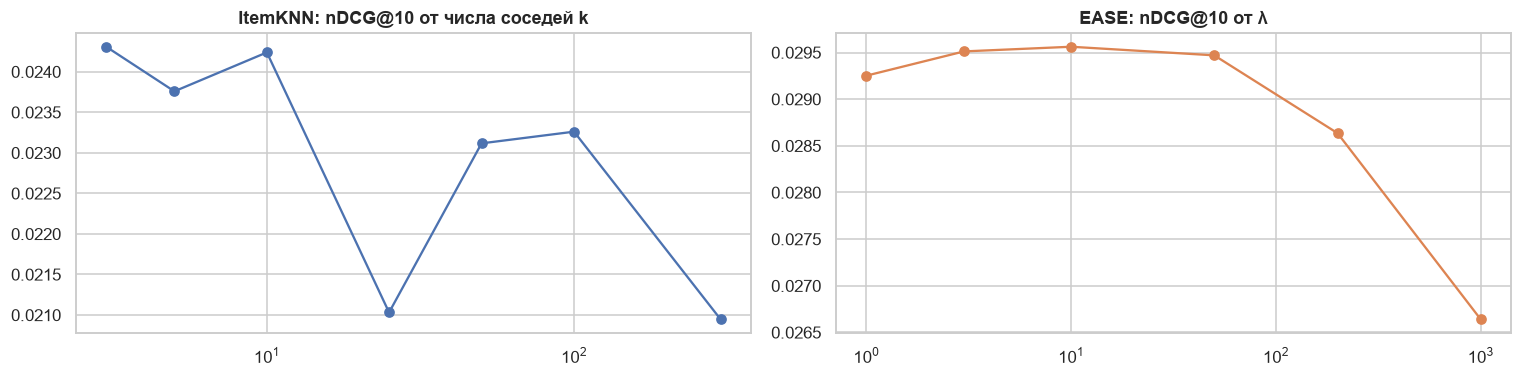

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
k_sorted = knn_grid.sort_values('k')
axes[0].plot(k_sorted.k, k_sorted['nDCG@10'], 'o-'); axes[0].set_xscale('log'); axes[0].set_title('ItemKNN: nDCG@10 от числа соседей k')
e_sorted = ease_grid.sort_values('lam')
axes[1].plot(e_sorted.lam, e_sorted['nDCG@10'], 'o-', color='C1'); axes[1].set_xscale('log'); axes[1].set_title('EASE: nDCG@10 от λ')
plt.tight_layout(); plt.show()

**Выводы по 6.2.**
- **ItemKNN:** лучше всего очень малое число соседей ($k=3$–$10$): значимы только самые сильные связи «прочитал A → прочитал B» (статьи из одной новостной истории), а длинный хвост слабых соседей добавляет шум.
- **EASE:** качество слабо зависит от $\lambda$ в диапазоне 1–50 и падает при сильной регуляризации ($\lambda \ge 200$), которая «размывает» item-item связи свежих статей с малым числом кликов. Выбрано $\lambda=10$.
- **ALS:** выигрывают модели с большим числом факторов (256) и малым $\alpha$: высокий $\alpha$ переоценивает уверенность в долгих прочтениях старых статей. Прирост от 128 к 256 факторам невелик при удвоении времени обучения, поэтому дальнейшее увеличение не проверялось.

## 7. Оценка на тестовой выборке и сравнение методов

Модели с выбранными гиперпараметрами обучаются на 14 днях до $T_{test}$ и оцениваются на следующих 24 часах. Каждая модель оценивается в двух режимах:
- **полный каталог** — кандидаты все статьи из обучения;
- **с фильтром свежести** — кандидаты только статьи, которые читали за последние $h_{pool}$ часов.

In [ ]:
test_ctx = metric_context(test)
test_pool = test.recent_counts(BEST_POOL_H) > 0
trend_test = TrendPop(BEST_TREND_H).fit(test)
primitive = np.argsort(-trend_test.pop)[:K]         

models = {'MostPop': MostPop(), f'TrendPop({BEST_TREND_H}h)': TrendPop(BEST_TREND_H),
          'ItemKNN': ItemKNN(**BEST['ItemKNN']), 'EASE': EASE(**BEST['EASE']), 'ALS': ALS(**BEST['ALS'])}
results, per_user, recs = {}, {}, {}
for name, model in models.items():
    model.fit(test)
    for regime, pool in [('полный каталог', None), ('фильтр свежести', test_pool)]:
        if name.startswith('TrendPop') and pool is not None:
            continue                                     
        m, pu, R = run(model, test, test_ctx, pool=pool, primitive=primitive, fit=False)
        results[(name, regime)], per_user[(name, regime)], recs[(name, regime)] = m, pu, R

METRICS = ['Precision@10', 'Recall@10', 'HitRate@10', 'nDCG@10', 'MAP@10', 'MRR@10',
           'Coverage@10', 'Novelty@10', 'ILD@10', 'Serendipity@10']
res = pd.DataFrame(results).T[METRICS]
res.index.names = ['модель', 'режим']
res.style.format('{:.4f}').background_gradient(cmap='Greens', axis=0)

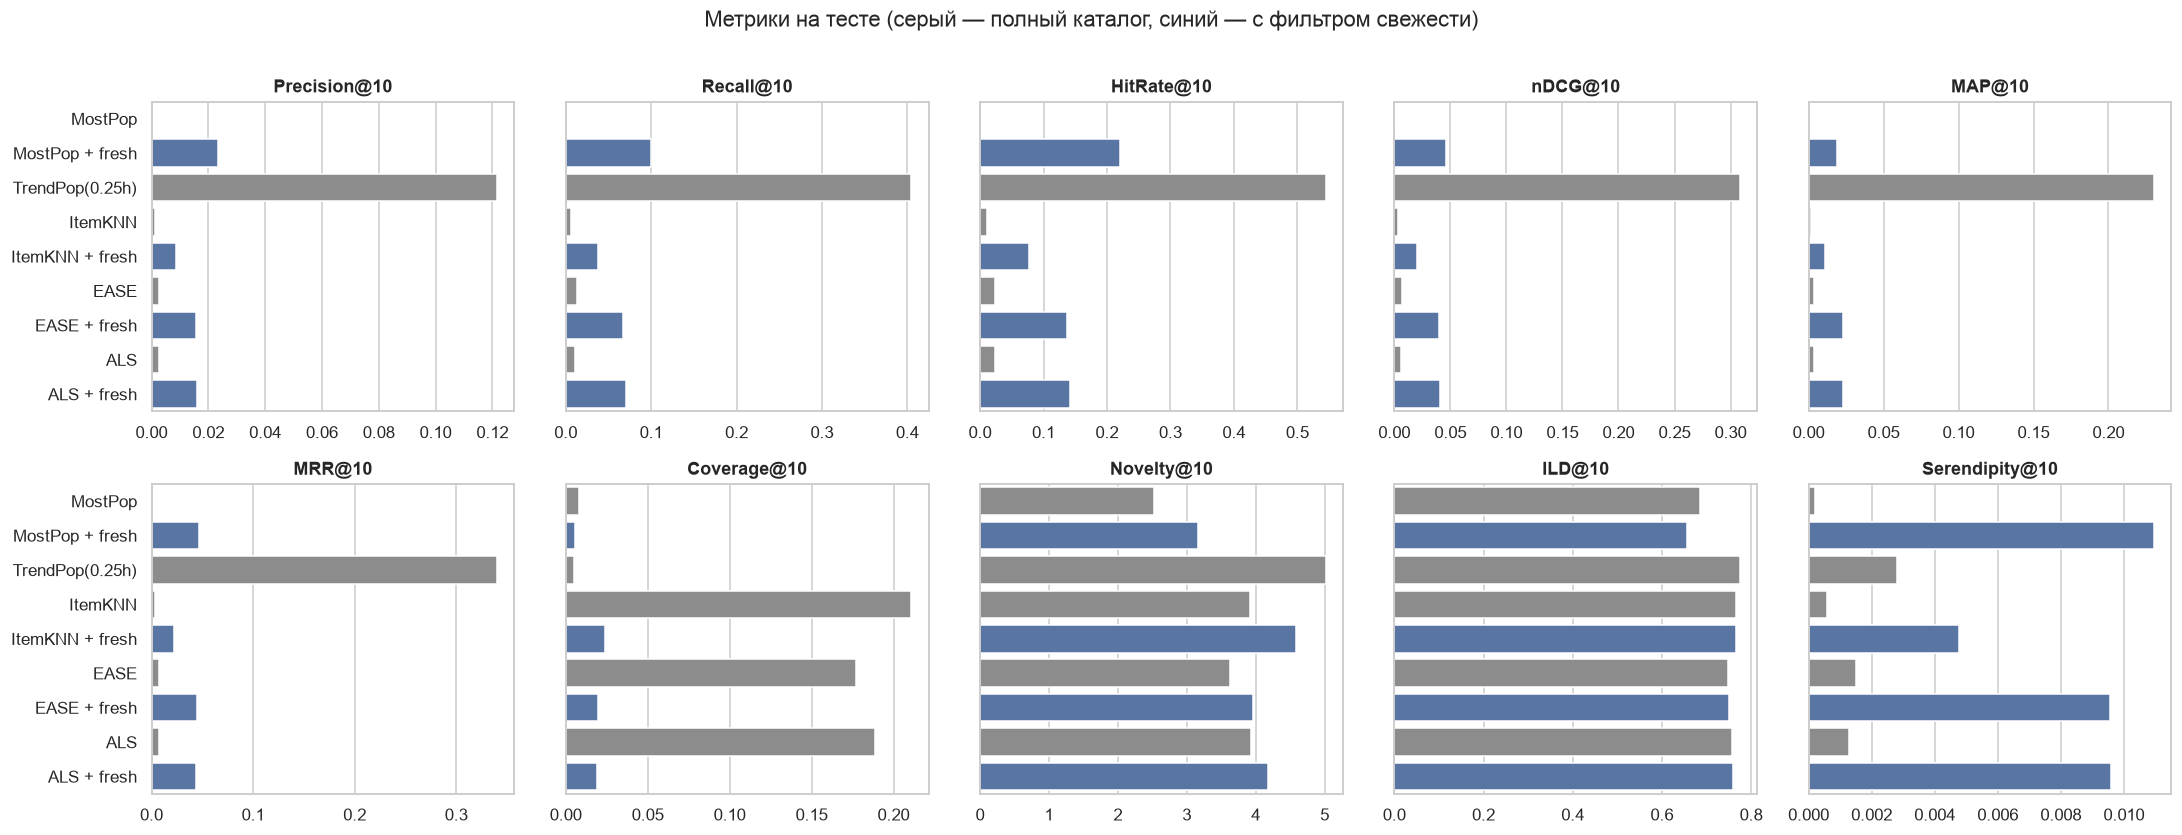

In [28]:
plot_df = res.reset_index()
plot_df['модель (режим)'] = plot_df['модель'] + np.where(plot_df['режим'] == 'фильтр свежести', ' + fresh', '')
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5), sharey=True)
for ax, m in zip(axes.ravel(), METRICS):
    sns.barplot(data=plot_df, y='модель (режим)', x=m, hue='режим', dodge=False, ax=ax, legend=False,
                palette={'полный каталог': 'C7', 'фильтр свежести': 'C0'})
    ax.set_title(m); ax.set_xlabel(''); ax.set_ylabel('')
plt.suptitle('Метрики на тесте (серый — полный каталог, синий — с фильтром свежести)', y=1.01)
plt.tight_layout(); plt.show()

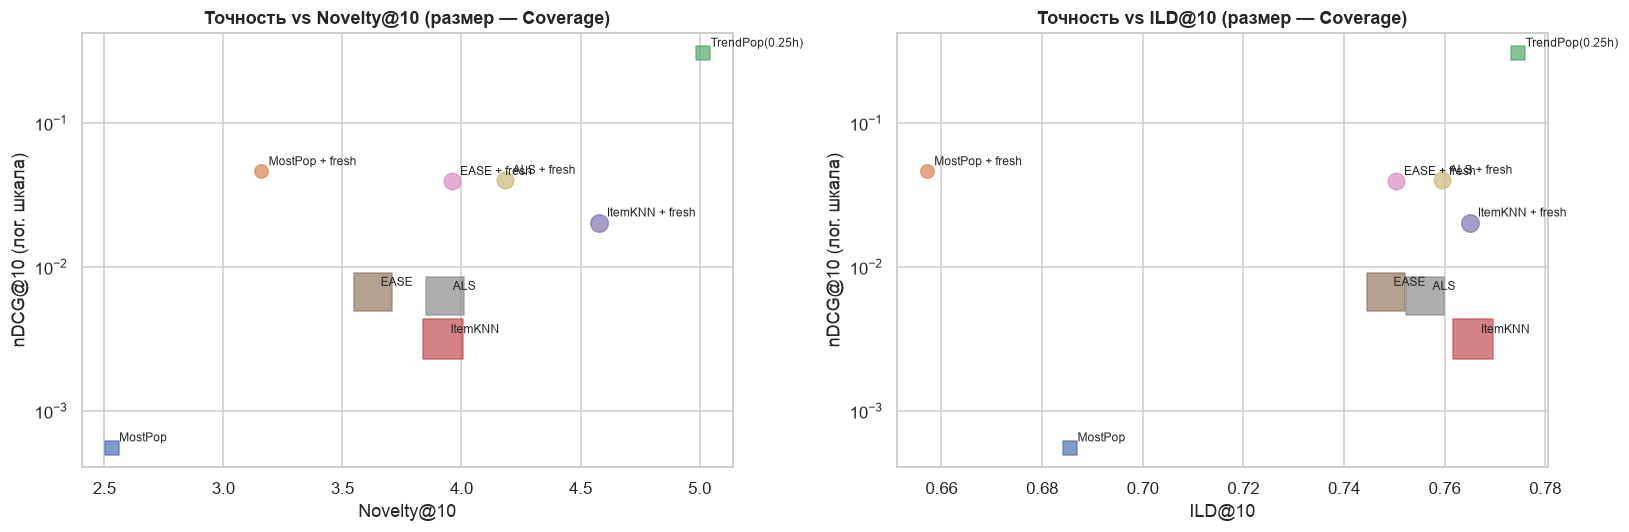

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, x in zip(axes, ['Novelty@10', 'ILD@10']):
    for (name, regime), row in res.iterrows():
        mk = 'o' if regime == 'фильтр свежести' else 's'
        ax.scatter(row[x], row['nDCG@10'], s=60 + 3000 * row['Coverage@10'], marker=mk, alpha=0.7)
        ax.annotate(name + (' + fresh' if mk == 'o' else ''), (row[x], row['nDCG@10']), fontsize=8,
                    xytext=(5, 4), textcoords='offset points')
    ax.set_yscale('log'); ax.set_xlabel(x); ax.set_ylabel('nDCG@10 (лог. шкала)'); ax.set_title(f'Точность vs {x} (размер — Coverage)')
plt.tight_layout(); plt.show()

**Анализ по сегментам пользователей.** Разобьём тестовых пользователей на квартили по числу кликов в обучении и посмотрим nDCG@10 персонализированных моделей и тренд-бейзлайна.

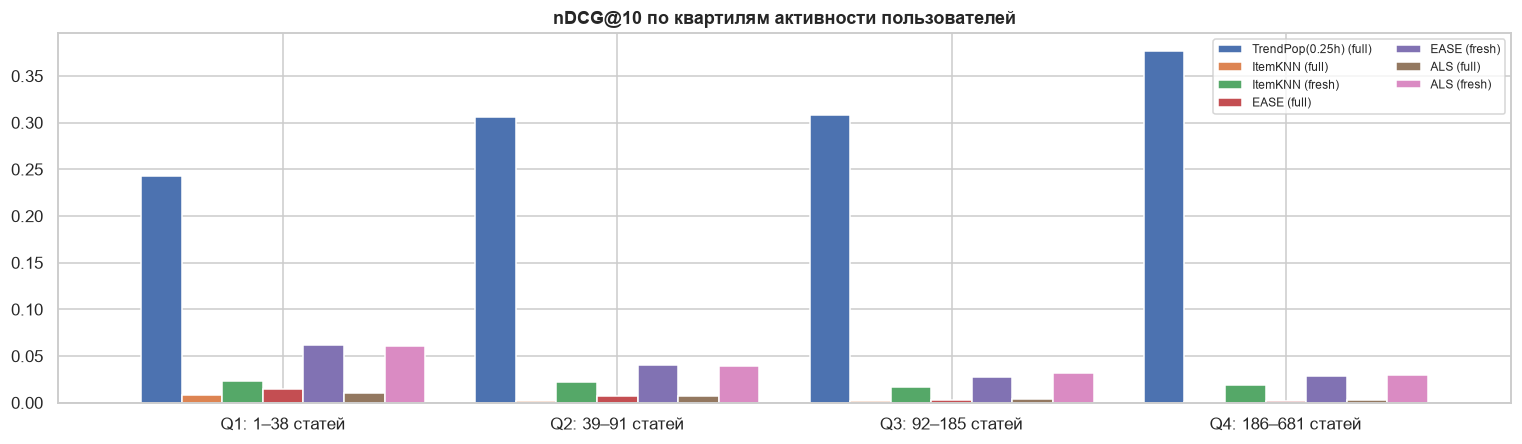

,TrendPop(0.25h) (full),ItemKNN (full),ItemKNN (fresh),EASE (full),EASE (fresh),ALS (full),ALS (fresh)
Q1: 1–38 статей,0.2429,0.0086,0.0235,0.0147,0.0621,0.0108,0.0612
Q2: 39–91 статей,0.3057,0.0016,0.0227,0.0070,0.0403,0.0067,0.0389
Q3: 92–185 статей,0.3077,0.0017,0.0167,0.0033,0.0279,0.0044,0.0318
Q4: 186–681 статей,0.3770,0.0008,0.0187,0.0019,0.0281,0.0033,0.0296


In [30]:
activity = np.asarray(test.X[test.eval_users].sum(1)).ravel()
segment = pd.qcut(activity, 4, labels=[f'Q{i}' for i in range(1, 5)])
seg_edges = pd.Series(activity).groupby(segment, observed=True).agg(['min', 'max'])
seg_names = {q: f'{q}: {int(r["min"])}–{int(r["max"])} статей' for q, r in seg_edges.iterrows()}
seg = pd.DataFrame({f'{n} ({"fresh" if r == "фильтр свежести" else "full"})': pd.Series(pu['nDCG@10']).groupby(segment, observed=True).mean()
                    for (n, r), pu in per_user.items() if n != 'MostPop'})
seg.index = seg.index.map(seg_names)
ax = seg.plot.bar(figsize=(14, 4.2), rot=0, width=0.85)
ax.set_title('nDCG@10 по квартилям активности пользователей'); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()
seg.style.format('{:.4f}').background_gradient(cmap='Greens', axis=1)

In [ ]:
title_of = articles.set_index('article_id').title
u_pos = int(np.argsort(-activity)[len(activity) // 3])  
u = test.eval_users[u_pos]
uid = test.users[u]
hist_u = test.train[test.train.user_id == uid].sort_values('ts').tail(5)
print(f'Пользователь {uid}; последние прочитанные статьи:')
for _, r in hist_u.iterrows():
    print(f'   {r.ts:%d.%m %H:%M}  [{cat_of.get(r.article_id)}] {title_of.get(r.article_id)}')
print('В тесте прочитал:', '; '.join(title_of.get(test.items[i]) for i in test.gt[u_pos]))
for key in [(f'TrendPop({BEST_TREND_H}h)', 'полный каталог'), ('ALS', 'фильтр свежести'), ('EASE', 'фильтр свежести')]:
    R = recs[key][u_pos]
    print(f'\n{key[0]} ({key[1]}):')
    for rank, i in enumerate(R[:5], 1):
        hit = '✔' if i in test.gt[u_pos] else ' '
        print(f'  {hit} {rank}. [{cat_of.get(test.items[i])}] {title_of.get(test.items[i])}')

Пользователь 1995120; последние прочитанные статьи:
   24.05 05:37  [nyheder] Messerschmidt i dyb restaurant-sorg: - Ærgerligt!
   24.05 05:37  [underholdning] Tv-kendis jubler: Jeg er kræftfri
   24.05 05:37  [nyheder] Konservativ borgmester har brugt skattekroner på koncerter
   24.05 05:38  [nyheder] DMI: Solen er tilbage!
   24.05 05:39  [sport] Raser mod FC Barcelona: Takker russerne
В тесте прочитал: Drabssag opklaret efter 48 år; Nervøs Tessa: Det var voldtægt; Ekspert: Åbenlys irritationsfaktor for Mette F.; Norwegian sagsøges ... af Norwegian; Bitter Armstrong: Han er en forbandet klovn!; Køge får største kvindeturnering på dansk grund i et årti

TrendPop(0.25h) (полный каталог):
  ✔ 1. [musik] Nervøs Tessa: Det var voldtægt
  ✔ 2. [nyheder] Norwegian sagsøges ... af Norwegian
  ✔ 3. [nyheder] Ekspert: Åbenlys irritationsfaktor for Mette F.
  ✔ 4. [sport] Bitter Armstrong: Han er en forbandet klovn!
  ✔ 5. [krimi] Drabssag opklaret efter 48 år

ALS (фильтр свежести):
    1. [s

### Интерпретация результатов

**1. Неперсонализированные модели.** Глобальный **MostPop** почти бесполезен (nDCG@10 = 0,0006): он рекомендует хиты двухнедельной давности, которые уже никто не читает. Ограничение тем же фильтром свежести поднимает его в ~80 раз (0,046). **TrendPop (15 мин)** — безусловный лидер: nDCG@10 ≈ 0,31, Recall@10 ≈ 0,40, хотя бы одно попадание получают 54% пользователей. В новостях «что читают прямо сейчас» — главный сигнал.

**2. Персонализированные модели в полном каталоге** (ItemKNN, EASE, ALS) показывают nDCG@10 < 0,01: они хорошо выучивают вкусы пользователя, но не знают о времени и предлагают устаревшие статьи. Зато у них максимальное покрытие каталога (18–21%) — платой за «персональность» является низкая актуальность.

**3. С фильтром свежести** точность коллаборативных моделей растёт в 6–7 раз: ALS и EASE ≈ 0,040, ItemKNN ≈ 0,020 по nDCG@10. Среди CF-моделей лучшие — **ALS и EASE** (практически вровень), ItemKNN вдвое слабее: косинусная близость на редких совместных прочтениях свежих статей шумная, а EASE и ALS обобщают через глобальную структуру матрицы. Однако даже с фильтром они примерно в 7–8 раз уступают TrendPop и даже не превосходят MostPop + фильтр.

**4. Почему CF проигрывает популярности.** Тестовые тёплые статьи опубликованы за минуты–часы до $T$ и имеют мало кликов в обучении, поэтому их латентные векторы/веса почти не обучены. Анализ по сегментам это подтверждает: у TrendPop nDCG растёт с активностью пользователя (активные читают «всё главное»), а у CF-моделей, наоборот, лучше всего результаты на **малоактивных** пользователях (Q1) — по мере роста истории модели всё сильнее тянутся к старым статьям из прошлых интересов.

**5. Метрики ранжирования.** MAP@10 и MRR@10 ведут себя согласованно с nDCG@10: порядок моделей одинаков, то есть различия не вызваны одной лишь метрикой. MRR TrendPop ≈ 0,34 — первое попадание в среднем находится в пределах первых трёх позиций.

**6. Beyond-accuracy метрики.**
- *Coverage:* у популярностных моделей один и тот же список для всех (< 1% каталога); у CF в полном каталоге — 18–21%, с фильтром — ~2% (пул живых статей мал).
- *Novelty:* максимальна у TrendPop (≈ 5,0 бит): новые статьи ещё мало кто читал в обучении, поэтому по исторической популярности они «новые». MostPop — минимальна (2,5 бита), он рекомендует то, что видели почти все.
- *ILD:* у всех моделей 0,66–0,78; MostPop наименее разнообразен (несколько хитов из одной категории), TrendPop и ItemKNN — наиболее.
- *Serendipity:* у TrendPop она около нуля по определению (он и есть «примитивная» модель); персонализированные модели с фильтром дают в ~3 раза больше «неожиданных» попаданий (≈ 0,01), т.е. находят релевантные статьи вне очевидного списка трендов — именно в этом их ценность.

**7. Качественный пример** показывает то же: TrendPop угадывает статьи, которые читают все, а ALS/EASE предлагают статьи по интересам пользователя (спорт, шоу-бизнес), но не те, что он прочёл в тот день.

## 8. Улучшение качества рекомендаций

### 8.1 Гибридный рекомендатель

Из сравнения следует: «что сейчас популярно» почти полностью определяет клики, а коллаборативные модели хорошо знают *вкусы* пользователя, но плохо знают *актуальность*. Объединим сильные стороны — **гибридный двухэтапный рекомендатель** (стандартная схема «генерация кандидатов → ранжирование»):

1. **Кандидаты:** $N$ самых популярных статей за последние $h$ часов (TrendPop).
2. **Ранжирование:** $s(u,i)=\frac{\log(1+pop_h(i))}{\log(1+\max pop_h)} + w\cdot \text{rank}_{CF}(u,i)$, где $\text{rank}_{CF}\in[0,1]$ — нормированный ранг статьи среди кандидатов по скору коллаборативной модели (ALS или EASE). Ранговая нормировка делает слагаемые сопоставимыми независимо от шкалы скоров модели.

$N$ и $w$ подбираются на валидации.

,cf,N,w,nDCG@10,Recall@10,Coverage@10
0,ALS,100,0.0200,0.2310,0.3348,0.0049
1,ALS,50,0.0200,0.2308,0.3341,0.0049
2,ALS,30,0.0200,0.2307,0.3338,0.0055
3,EASE,100,0.0200,0.2305,0.3331,0.0049
4,EASE,50,0.0200,0.2303,0.3327,0.0049
5,EASE,30,0.0200,0.2302,0.3325,0.0055
6,ALS,20,0.0200,0.2298,0.3314,0.0244
7,EASE,20,0.0200,0.2291,0.3294,0.0242


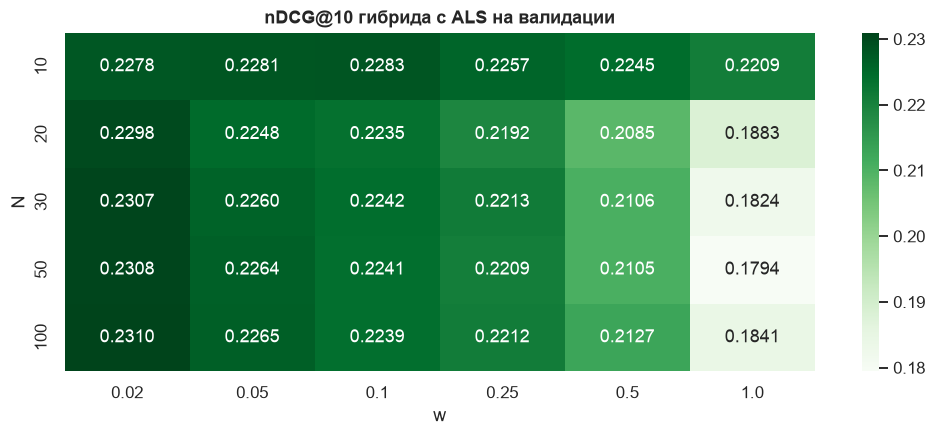

{'cf': 'ALS', 'N': 100, 'w': 0.02}

In [ ]:
class HybridRerank:
    def __init__(self, cf, trend, n_cand=30, w=1.0):
        self.cf, self.trend, self.n_cand, self.w = cf, trend, n_cand, w
        self.name = f'Hybrid(TrendPop + {cf.name})'
    def fit(self, split):                    
        return self
    def score(self, users):
        pop = self.trend.pop
        trend_s = (np.log1p(pop) / np.log1p(pop.max())).astype(np.float32)
        cand = np.argsort(-pop)[:self.n_cand]
        S_cf = np.asarray(self.cf.score(users))[:, cand]
        cf_rank = S_cf.argsort(1).argsort(1) / (self.n_cand - 1)
        out = np.tile(trend_s - 1e9, (len(users), 1))      
        out[:, cand] = trend_s[cand] + self.w * cf_rank
        return out


trend_val = TrendPop(BEST_TREND_H).fit(val)
cf_val = {'ALS': ALS(**BEST['ALS']).fit(val), 'EASE': EASE(**BEST['EASE']).fit(val)}
rows = []
for cf_name, cf in cf_val.items():
    for n in [10, 20, 30, 50, 100]:
        for w in [0.02, 0.05, 0.1, 0.25, 0.5, 1.0]:
            m, _, _ = run(HybridRerank(cf, trend_val, n, w), val, val_ctx, fit=False)
            rows.append({'cf': cf_name, 'N': n, 'w': w, **m[['nDCG@10', 'Recall@10', 'Coverage@10']].to_dict()})
hyb_grid = pd.DataFrame(rows).sort_values('nDCG@10', ascending=False).reset_index(drop=True)
display(hyb_grid.head(8).style.format(precision=4).set_caption('Гибрид: лучшие конфигурации на валидации'))

pivot = hyb_grid[hyb_grid.cf == hyb_grid.cf[0]].pivot(index='N', columns='w', values='nDCG@10')
ax = sns.heatmap(pivot, annot=True, fmt='.4f', cmap='Greens')
ax.set_title(f'nDCG@10 гибрида с {hyb_grid.cf[0]} на валидации'); plt.show()
BEST_HYB = hyb_grid.loc[0, ['cf', 'N', 'w']].to_dict()
BEST_HYB

In [33]:
for cf_name in ['ALS', 'EASE']:
    sub = hyb_grid[hyb_grid.cf == cf_name].iloc[0]
    hyb = HybridRerank(models[cf_name], trend_test, int(sub.N), float(sub.w))
    m, pu, R = run(hyb, test, test_ctx, primitive=primitive, fit=False, label=f'Hybrid(TrendPop + {cf_name})')
    results[(m.name, f'N={int(sub.N)}, w={sub.w}')], per_user[(m.name, 'hybrid')], recs[(m.name, 'hybrid')] = m, pu, R

final = pd.DataFrame(results).T[METRICS]
final.index.names = ['модель', 'режим']
final = final.sort_values('nDCG@10', ascending=False)
final.style.format('{:.4f}').background_gradient(cmap='Greens', axis=0)

,,Precision@10,Recall@10,HitRate@10,nDCG@10,MAP@10,MRR@10,Coverage@10,Novelty@10,ILD@10,Serendipity@10
модель,режим,,,,,,,,,,
Hybrid(TrendPop + ALS),"N=100, w=0.02",0.1216,0.4041,0.5440,0.3084,0.2308,0.3405,0.0047,5.0580,0.8008,0.0040
Hybrid(TrendPop + EASE),"N=100, w=0.02",0.1216,0.4043,0.5444,0.3083,0.2305,0.3405,0.0047,5.0494,0.7997,0.0039
TrendPop(0.25h),полный каталог,0.1216,0.4046,0.5444,0.3083,0.2305,0.3401,0.0047,5.0141,0.7746,0.0028
MostPop,фильтр свежести,0.0235,0.0999,0.2200,0.0463,0.0188,0.0463,0.0057,3.1582,0.6571,0.0110
ALS,фильтр свежести,0.0160,0.0701,0.1414,0.0404,0.0231,0.0437,0.0192,4.1831,0.7595,0.0096
EASE,фильтр свежести,0.0156,0.0668,0.1375,0.0396,0.0230,0.0446,0.0196,3.9623,0.7504,0.0096
ItemKNN,фильтр свежести,0.0087,0.0374,0.0771,0.0204,0.0108,0.0219,0.0237,4.5784,0.7651,0.0048
EASE,полный каталог,0.0026,0.0130,0.0239,0.0067,0.0035,0.0071,0.1770,3.6285,0.7483,0.0015
ALS,полный каталог,0.0026,0.0110,0.0229,0.0063,0.0034,0.0076,0.1890,3.9313,0.7561,0.0013


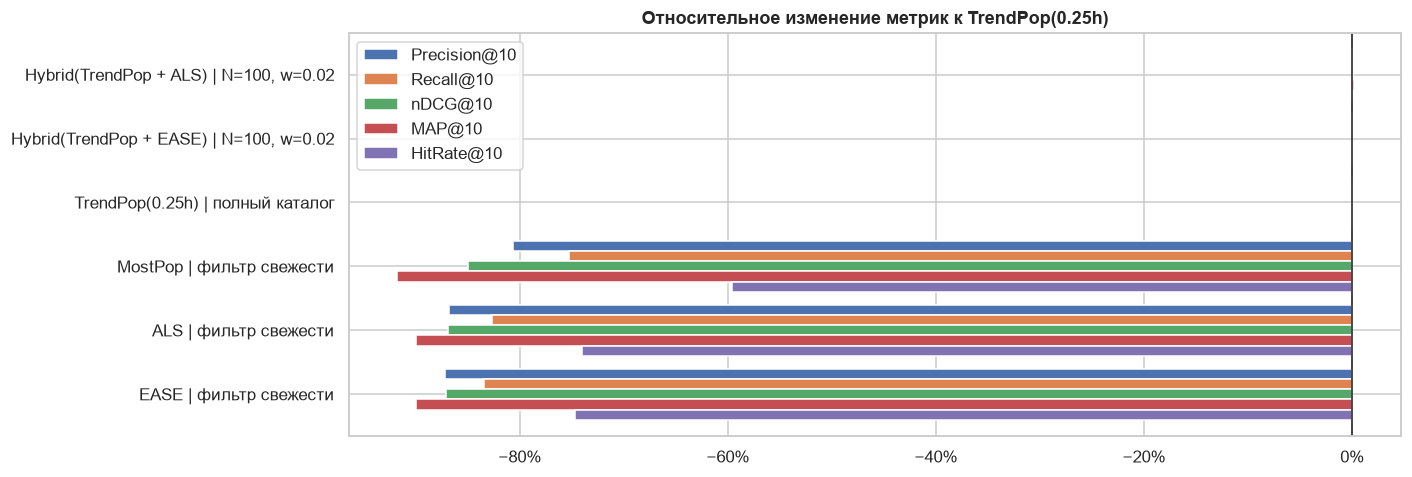

Hybrid(TrendPop + ALS) − TrendPop: ΔnDCG@10 = 0.0001, 95% ДИ [-0.0004; 0.0006]


In [ ]:
base = res.loc[(f'TrendPop({BEST_TREND_H}h)', 'полный каталог')]
top = final.head(6)
rel_gain = (top[['Precision@10', 'Recall@10', 'nDCG@10', 'MAP@10', 'HitRate@10']] / base[['Precision@10', 'Recall@10', 'nDCG@10', 'MAP@10', 'HitRate@10']] - 1)
rel_gain.index = [f'{a} | {b}' for a, b in rel_gain.index]
ax = rel_gain.plot.barh(figsize=(13, 4.5), width=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.axvline(0, c='k', lw=1)
ax.set_title(f'Относительное изменение метрик к TrendPop({BEST_TREND_H}h)'); ax.invert_yaxis()
plt.tight_layout(); plt.show()

best_h = f'Hybrid(TrendPop + {BEST_HYB["cf"]})'                 
a = per_user[(best_h, 'hybrid')]['nDCG@10']; b = per_user[(f'TrendPop({BEST_TREND_H}h)', 'полный каталог')]['nDCG@10']
rng = np.random.default_rng(SEED)
boot = [(a[idx] - b[idx]).mean() for idx in (rng.integers(0, len(a), len(a)) for _ in range(1000))]
print(f'{best_h} − TrendPop: ΔnDCG@10 = {(a - b).mean():.4f}, 95% ДИ [{np.percentile(boot, 2.5):.4f}; {np.percentile(boot, 97.5):.4f}]')

### 8.2 Длина окна обучения

В основном протоколе окно обучения фиксировано (14 дней), чтобы все модели сравнивались на одних и тех же пользователях. Проверим, как длина окна влияет на ALS.

In [ ]:
WINDOWS = [1, 2, 3, 5, 7, 14, 21]
window_tables = {}
for base_split, T0 in [('validation', T_VAL), ('test', T_TEST)]:
    rows, ndcg_by_user = [], {}
    for d in WINDOWS:
        s = make_split(log, T0, train_days=d)
        m, pu, _ = run(ALS(**BEST['ALS']), s, metric_context(s), pool=s.recent_counts(BEST_POOL_H) > 0, label=f'{d} дн.')
        ndcg_by_user[d] = pd.Series(pu['nDCG@10'], index=s.users[s.eval_users])
        rows.append({'статей в train': s.n_items, 'eval-пользователей': len(s.eval_users),
                     'холодных пользователей в тесте': s.stats['test: доля пар с холодным пользователем'],
                     'nDCG@10': m['nDCG@10']})
    common = sorted(set.intersection(*(set(v.index) for v in ndcg_by_user.values())))
    t = pd.DataFrame(rows, index=[f'{d} дн.' for d in WINDOWS])
    t['nDCG@10 (общие пользователи)'] = [ndcg_by_user[d].loc[common].mean() for d in WINDOWS]
    window_tables[base_split] = t
    display(t.style.format({'статей в train': '{:,.0f}', 'eval-пользователей': '{:,.0f}',
                            'холодных пользователей в тесте': '{:.1%}', 'nDCG@10': '{:.4f}',
                            'nDCG@10 (общие пользователи)': '{:.4f}'})
            .highlight_max(subset=['nDCG@10 (общие пользователи)'], color='#c6efce')
            .set_caption(f'ALS + фильтр свежести, {base_split}: длина окна обучения (общих пользователей: {len(common):,})'))

,статей в train,eval-пользователей,холодных пользователей в тесте,nDCG@10,nDCG@10 (общие пользователи)
1 дн.,"1,230","3,463",11.7%,0.0414,0.0419
2 дн.,"2,041","3,782",7.0%,0.0450,0.0475
3 дн.,"2,583","3,871",6.0%,0.0529,0.0559
5 дн.,"3,466","4,015",4.8%,0.0465,0.0500
7 дн.,"4,447","4,147",3.5%,0.0414,0.0447
14 дн.,"7,079","4,208",2.9%,0.0344,0.0368
21 дн.,"9,180","4,206",2.8%,0.0339,0.0357


,статей в train,eval-пользователей,холодных пользователей в тесте,nDCG@10,nDCG@10 (общие пользователи)
1 дн.,"1,432","3,790",12.2%,0.0182,0.0185
2 дн.,"2,061","4,206",7.0%,0.0785,0.0836
3 дн.,"2,746","4,376",5.3%,0.0685,0.0749
5 дн.,"3,632","4,480",4.3%,0.0468,0.0500
7 дн.,"4,426","4,570",3.6%,0.0436,0.0442
14 дн.,"7,176","4,682",3.1%,0.0404,0.0371
21 дн.,"9,258","4,707",3.1%,0.0402,0.0353


**Выводы по разделу 8.**
- **Гибрид TrendPop + CF.** На валидации оптимальный вес CF-слагаемого оказался минимальным в сетке ($w=0{,}02$): коллаборативный сигнал полезен лишь как способ разрешить «ничьи» между одинаково популярными статьями. На тесте разница с TrendPop статистически незначима (95% бутстреп-интервал для ΔnDCG@10 включает 0). Аналогичный эксперимент с переранжированием трендов по предпочтениям пользователя к категориям (вне ноутбука) дал прирост ≤ 1–2%, также в пределах шума. Вывод: при текущем протоколе (одна выдача на сутки, оценка только на тёплых статьях) «актуальность» полностью доминирует над «вкусом».
- **Короткое окно обучения** для коллаборативных моделей — устойчивое улучшение: на общих пользователях nDCG@10 ALS растёт с ~0,037 (14 дней) до ~0,056 на валидации (3 дня) и до ~0,08 на тесте (2–3 дня), т.е. в 1,5–2 раза. Модель меньше «помнит» неактуальные интересы, а матрица становится компактнее и быстрее обучается. Цена — рост доли холодных пользователей (с 3% до 5–7%), которым нужна выдача TrendPop; окно в 1 день уже слишком мало и ухудшает качество.
- **Фильтр свежести** (раздел 6–7) — самое сильное улучшение для CF-моделей: ×5–7 по nDCG@10.

### Дальнейшие предложения по улучшению

1. **Обновление трендов в реальном времени.** Оптимальное окно TrendPop — 15 минут, а выдача фиксируется на 24 часа. В продакшене тренды пересчитываются каждые несколько минут; оценка в режиме «пересчёт на каждый запрос» должна дать существенно лучший результат, чем статический список.
2. **Контентные признаки для холодного старта.** 88% тестовых кликов приходятся на статьи, неизвестные CF-моделям. Эмбеддинги заголовков и текстов (TF-IDF, мультиязычный BERT/ sentence-transformers для датского), категории, темы и NER позволяют строить профиль пользователя и ранжировать любые новые статьи (подход NRMS/LSTUR из MIND / EB-NeRD).
3. **Временное затухание весов** взаимодействий в ALS/EASE ($w_{ui}\cdot e^{-\Delta t/\tau}$) вместо жёсткого окна — плавный компромисс между «вкусом» и «актуальностью».
4. **Двухэтапная схема с обучаемым ранжировщиком.** Кандидаты (тренды + CF + контент) → градиентный бустинг (CatBoost/LightGBM, LambdaRank) на признаках: возраст статьи, популярность за 15 мин/1 ч/6 ч, CF-скоры, совпадение категории с профилем, тип устройства, время суток. Это стандартное решение призёров RecSys Challenge 2024.
5. **Сессионные модели** (GRU4Rec, SASRec): последовательность чтения внутри сессии хорошо предсказывает следующий клик (это подтверждает лучший результат ItemKNN при $k=3$).
6. **Протокол оценки в формате соревнования:** ранжирование статей из `article_ids_inview` (AUC, nDCG по показу) учитывает, что пользователь выбирает только из показанного — это ближе к онлайн-метрике CTR.
7. **Контроль разнообразия** (MMR / калибровка по категориям) при переранжировании, чтобы не терять в ILD и Coverage при росте точности.

## 9. Выводы

1. **Данные.** Выбран датасет EB-NeRD (RecSys Challenge 2024, Ekstra Bladet): 3,28 млн кликов 18,8 тыс. пользователей по 11 тыс. новостных статей за 4 недели. Объект рекомендации — статья, целевое событие — клик (неявный отклик). EDA выявил сильную разреженность (98,7%), длинный хвост популярности, выраженную суточную сезонность и главное — **очень короткий жизненный цикл новостей** (медиана возраста при клике 1,4 ч). Основная проблема качества — 29% дубликатов из-за пересечения окон логов; они удалены.
2. **Протокол.** Глобальное временное разбиение: 14 дней обучения → 24 часа теста, гиперпараметры подбирались на отдельном валидационном разбиении (сдвиг на сутки назад). 88% тестовых кликов приходятся на статьи, опубликованные после момента обучения, — холодный старт объектов является определяющей характеристикой задачи.
3. **Методы.** Реализованы модели четырёх семейств: популярностные (MostPop, TrendPop), соседская (ItemKNN), линейный автоэнкодер (EASE, закрытая формула) и матричная факторизация (ALS для неявного отклика с весами по времени чтения).
4. **Метрики.** Precision, Recall, HitRate (точность), nDCG, MAP, MRR (ранжирование), Coverage, Novelty, ILD, Serendipity (beyond-accuracy); реализация проверена на игрушечном примере.
5. **Результаты.** Лучшая модель — **TrendPop по последним 15 минутам** (nDCG@10 ≈ 0,31, Recall@10 ≈ 0,40, HitRate@10 ≈ 0,54). Коллаборативные модели без учёта времени практически бесполезны (nDCG < 0,01), с фильтром свежести — в 6–7 раз лучше (ALS ≈ EASE ≈ 0,04 > ItemKNN ≈ 0,02), но всё равно заметно уступают трендам. Их сильные стороны — покрытие каталога и serendipity: они находят релевантные статьи вне списка «что читают все».
6. **Улучшения.** Фильтр «живых» статей (×5–7) и короткое окно обучения 2–3 дня (×1,5–2) существенно улучшают CF-модели. Гибридное переранжирование трендов коллаборативным скором значимого прироста не дало: в этой постановке актуальность доминирует над персональными вкусами. Главные направления дальнейшей работы — тренды в реальном времени, контентные модели для холодных статей и обучаемый ранжировщик поверх кандидатов из нескольких источников.